# 05 - A supervised extractor for TabPFN (v5 to v9; small and medium datasets, and the 3 worst datasets)

The cheap TabPFN of notebook 04 (v4) beats QUANT + ExtraTrees on most datasets (notebook 06), but it loses most on
a few datasets whose class depends on a short local pattern (section 2 shows why). This notebook builds a different
extractor: instead of producing a fixed set of features and leaving the choice to a filter, it looks at the training
labels and returns at most 250 strong, non-redundant features itself; TabPFN uses all of them.

**The supervised extractor** (`quant_tabpfn.SupervisedExtractor`, `run.py --quant supervised`), all on the training
data:
1. **candidates**: the interval features of v4 (4 levels of pieces, min and max + mean, spread and trend per piece)
   of QUANT's four views and of lag-d differences, plus, step by step:
   - a **shape-only view** (`--znorm`): every series rescaled to mean 0 and spread 1;
   - **catch22** (`--catch22`): 22 whole-series features (autocorrelation, share of rising steps, ...) of the series
     and of its change;
   - **pattern templates** (`--templates`): short windows taken from training series, at least one per class (up to
     3, at most 60), each giving one feature: the smallest distance between the template and any window of a series;
2. a **relevance check**: candidates that do not separate the classes (ANOVA, p >= 0.05) are dropped;
3. a **greedy selection**: down the ranking, a feature is taken only if it is not a near-copy (|correlation| >= 0.95)
   of one already taken, up to 250.

| Version | What changes | Files |
|---|---|---|
| **QUANT + ExtraTrees** (reference) | the original QUANT (v1), all cores | `v1_ucr142_allcores-cpu.csv` (notebook 06) |
| **v4 (cheap TabPFN)** (reference) | about 450 lean features, ANOVA then ExtraTrees pick 200 | `v4_tabpfn-e2f200-both_ucr142_allcores-gpu.csv` (notebook 06) |
| **v5-sel** | the supervised selection alone (QUANT's views + lag-4 and lag-16) | `v5-sel_tabpfn-e2f250_{list}_allcores-gpu.csv` |
| **v5-shape** | + the shape-only view | `v5-shape_...` |
| **v5-catch22** | + catch22 | `v5-catch22_...` |
| **v5-templates** | + pattern templates | `v5-templates_...` |
| **v6** | v5-templates without the shape-only view and lag-4 (they mostly repeat other views, section 7), the budget filled (`--fill_budget`), catch22 on a shortened copy of long, smooth series (`--c22_shorten`) | `v6_tabpfn-e2f250_{list}_allcores-gpu.csv` |
| **v7** | v6 with ExtraTrees importance in the selection (`--supervised_rank both`, as v4's "both") and a smaller budget for datasets with more than 2000 series (`--relative_budget --relative_min 150`) | `v7_...` |
| **v8-lag4** | v7 with lag-4 added back | `v8-lag4_...` |
| **v8** | v7 with the lag-d views chosen per dataset (`--lags auto`: d = 2, 4, 8, ... up to a quarter of the series length, at most 64) | `v8_...` |
| **v9 (200 features)** | v8 with two speed fixes (catch22 and the templates computed once for all fill rounds; finer pieces only down to 1/16), 200 features on every dataset (no size rule) and a fifth of QUANT's quantiles, median kept, on QUANT's four views (`--quantile_fraction 0.2`) | `v9_tabpfn-e2f200_ucr142_allcores-gpu.csv` (notebook 06) |

QUANT + ExtraTrees, v4 and v9 come from the full runs of notebook 06 (142 datasets x 30 resamples), taking only the
datasets and resamples of each list. Every v5 to v8 file has a `_selection.csv` next to it: what happened to every
candidate (source, kind, piece size, position; kept / dropped as irrelevant / as a near-copy of which source / over
budget).

| Setting | Value |
|---|---|
| lists | **small** and **medium** (`smoke-*.txt`, 3 resamples, 15 runs; v6 to v9 also 30 resamples on the small list); **worst3** (`worst3.txt`: ShapeletSim, ToeSegmentation2, ToeSegmentation1; 30 resamples, 90 runs); section 11: v8 on all 142 datasets and **worst10** (`worst10.txt`, the 10 datasets where v8 loses most to QUANT + ExtraTrees; 30 resamples) |
| TabPFN | 2 passes, all the extractor's features (at most 250; v9: 200), model cache |
| hardware | all CPU cores + GPU (QUANT + ExtraTrees: all CPU cores); seed 0 |

**How the files are produced:** see `experiments.md`, v3 to v9.

- **Section 2** - why v4 loses on its 3 worst datasets.
- **Section 3** - accuracy and time of every version; the 3 worst datasets and the small ones (30 resamples) one by one.
- **Section 4** - the funnel: candidates, relevant, kept, by source (v5-templates and v6).
- **Section 5** - why features are dropped, by source.
- **Section 6** - which kinds and piece sizes are kept how often.
- **Section 7** - near-copies: which source duplicates which.
- **Section 8** - catch22: which of its features are kept.
- **Section 9** - pattern templates: how often they are kept.
- **Section 10** - which lag-d views each dataset uses (v8).
- **Section 11** - v8 on all 142 datasets, and its 10 worst: the classifier or the features? And v9 there.
- **Section 12** - from v8 to v9: where v8's time goes, which of QUANT's features TabPFN needs, the check on the
  other lists, and 200 features instead of 250.

All results are shown as plots; times in seconds on linear axes. Caveat: smoke tests (3 resamples on the small and
medium lists) are a first signal; the full benchmark is in notebook 06.

## 1. Settings and data

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# the shared names, colours, plot style and loading of all notebooks: notebooks/common.py
from common import BETTER, EQUAL, MUTED, RESULTS_DIR, TEXT, WORSE, dataset_list, load_runs, read_split, style, wdl_counts

style()
LISTS = ["smoke-small", "smoke-medium", "worst3"]
LIST_NAMES = {"smoke-small": "small datasets", "smoke-medium": "medium datasets", "worst3": "the 3 worst datasets"}
RESAMPLES = {"smoke-small": 3, "smoke-medium": 3, "worst3": 30}
# every version: None = a reference from notebook 06, else the start of its file name
STEPS = {"QUANT + ExtraTrees": None, "v4 (cheap TabPFN)": None,
         "v5-sel": "v5-sel", "v5-shape": "v5-shape", "v5-catch22": "v5-catch22", "v5-templates": "v5-templates",
         "v6": "v6", "v7": "v7", "v8-lag4": "v8-lag4", "v8": "v8", "v9 (200 features)": None}
STEP_COLORS = dict(zip(STEPS, ["#8c8b85", "#eda100", "#9cc3ef", "#2a78d6", "#4a3aa7", "#008300",
                               "#5cc4b8", "#c9a400", "#8a7300", "#e0457b", "#8e1b4f"]))
SMALL_30 = ["QUANT + ExtraTrees", "v4 (cheap TabPFN)", "v6", "v7", "v8-lag4", "v8", "v9 (200 features)"]   # 30 resamples on the small list
REFERENCE = "v4 (cheap TabPFN)"                  # the W/D/L counts of section 3 are against this one
key = ["dataset", "resample"]
WORST3 = dataset_list("worst3")

def load(name):
    d = load_runs(RESULTS_DIR / name)
    return d[d["status"] == "ok"]

full_runs = {"QUANT + ExtraTrees": load("v1_ucr142_allcores-cpu.csv"),                 # the full runs of notebook 06
             "v4 (cheap TabPFN)": load("v4_tabpfn-e2f200-both_ucr142_allcores-gpu.csv"),
             "v9 (200 features)": load("v9_tabpfn-e2f200_ucr142_allcores-gpu.csv")}
RUNS = {}                                                              # (list, version) -> runs on RESAMPLES
SELECTION = {}                                                         # (list, version) -> what happened to the candidates
SMALL_RUNS = {}                                                        # version -> runs on the small list, 30 resamples
for lst in LISTS:
    for step, prefix in STEPS.items():
        if prefix is None:                       # the same datasets as the list
            d = full_runs[step][full_runs[step]["dataset"].isin(dataset_list(lst))]
        else:
            name = f"{prefix}_tabpfn-e2f250_{lst}_allcores-gpu"
            d = load(f"{name}.csv")
            SELECTION[(lst, step)] = pd.read_csv(RESULTS_DIR / f"{name}_selection.csv")
        RUNS[(lst, step)] = d[d["resample"] < RESAMPLES[lst]]                # every version on the same resamples
        if lst == "smoke-small" and step in SMALL_30:
            SMALL_RUNS[step] = d
print({f"{lst}/{step}": len(d) for (lst, step), d in RUNS.items()})
print("small list, 30 resamples:", {step: len(d) for step, d in SMALL_RUNS.items()})

{'smoke-small/QUANT + ExtraTrees': 15, 'smoke-small/v4 (cheap TabPFN)': 15, 'smoke-small/v5-sel': 15, 'smoke-small/v5-shape': 15, 'smoke-small/v5-catch22': 15, 'smoke-small/v5-templates': 15, 'smoke-small/v6': 15, 'smoke-small/v7': 15, 'smoke-small/v8-lag4': 15, 'smoke-small/v8': 15, 'smoke-small/v9 (200 features)': 15, 'smoke-medium/QUANT + ExtraTrees': 15, 'smoke-medium/v4 (cheap TabPFN)': 15, 'smoke-medium/v5-sel': 15, 'smoke-medium/v5-shape': 15, 'smoke-medium/v5-catch22': 15, 'smoke-medium/v5-templates': 15, 'smoke-medium/v6': 15, 'smoke-medium/v7': 15, 'smoke-medium/v8-lag4': 15, 'smoke-medium/v8': 15, 'smoke-medium/v9 (200 features)': 15, 'worst3/QUANT + ExtraTrees': 90, 'worst3/v4 (cheap TabPFN)': 90, 'worst3/v5-sel': 90, 'worst3/v5-shape': 90, 'worst3/v5-catch22': 90, 'worst3/v5-templates': 90, 'worst3/v6': 90, 'worst3/v7': 90, 'worst3/v8-lag4': 90, 'worst3/v8': 90, 'worst3/v9 (200 features)': 90}
small list, 30 resamples: {'QUANT + ExtraTrees': 150, 'v4 (cheap TabPFN)': 150, 

## 2. Why v4 loses on its 3 worst datasets

On all 142 datasets (notebook 06) v4 loses most to QUANT + ExtraTrees on ShapeletSim, ToeSegmentation2 and
ToeSegmentation1: 2 classes, 20 to 40 training cases, and a class that depends on a short local pattern at a varying
position (ShapeletSim: a small shape hidden in noise; ToeSegmentation: a short step pattern in a gait recording).
Two diagnostic runs separate the classifier from the features (30 resamples each): ExtraTrees on v4's features (all
450), and TabPFN on QUANT's original features (2 passes x 200 and 8 passes x 500 features, from the v3 settings).

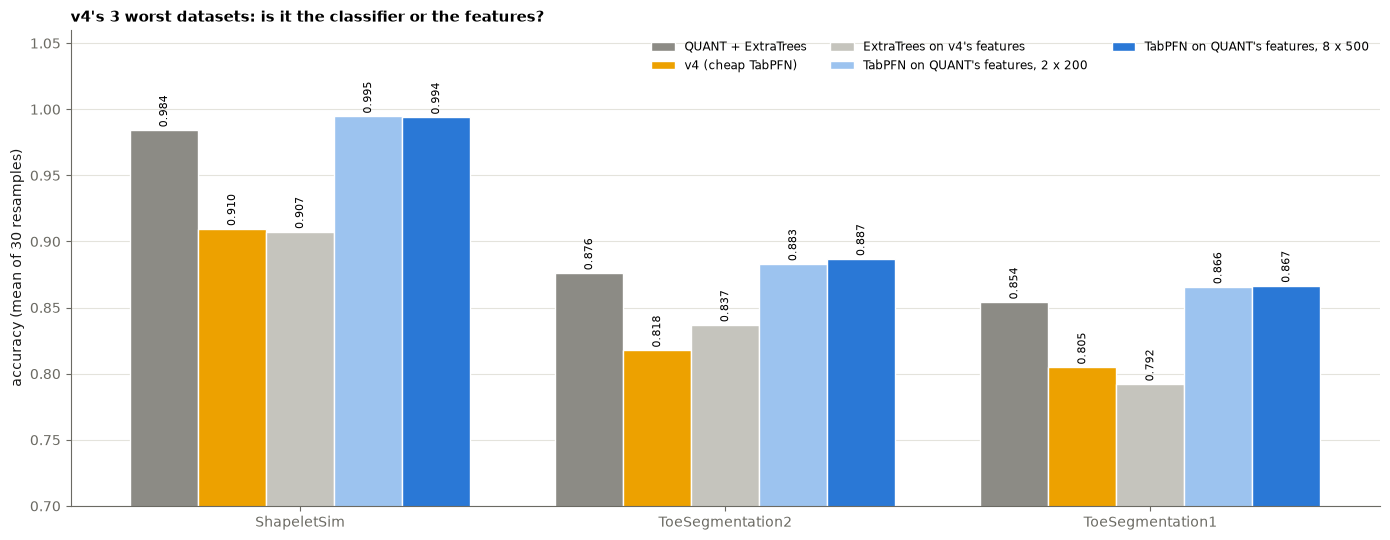

In [2]:
DIAGNOSIS = {"QUANT + ExtraTrees": full_runs["QUANT + ExtraTrees"],
             "v4 (cheap TabPFN)": full_runs["v4 (cheap TabPFN)"],
             "ExtraTrees on v4's features": load("v4_extratrees_worst3_allcores-cpu.csv"),
             "TabPFN on QUANT's features, 2 x 200": load("v3-quant_tabpfn-e2f200-cache_worst3_allcores-gpu.csv"),
             "TabPFN on QUANT's features, 8 x 500": load("v3-quant_tabpfn-e8f500-cache_worst3_allcores-gpu.csv")}
DIAGNOSIS_COLORS = ["#8c8b85", "#eda100", "#c5c4bd", "#9cc3ef", "#2a78d6"]
fig, ax = plt.subplots(figsize=(14, 5.5))
width = 0.16
for k, ((label, runs), color) in enumerate(zip(DIAGNOSIS.items(), DIAGNOSIS_COLORS)):
    values = runs[runs["dataset"].isin(WORST3)].groupby("dataset")["accuracy"].mean().reindex(WORST3)
    bars = ax.bar(np.arange(3) + (k - 2) * width, values, width, color=color, edgecolor="white", label=label)
    ax.bar_label(bars, fmt="{:.3f}", padding=2, fontsize=8, rotation=90)
ax.set_xticks(range(3), WORST3)
ax.set_ylim(0.7, 1.06)
ax.set_ylabel("accuracy (mean of 30 resamples)")
ax.set_title("v4's 3 worst datasets: is it the classifier or the features?", loc="left")
ax.legend(loc="upper right", ncol=3, frameon=False, fontsize=8.5)
ax.grid(True, axis="y")
ax.grid(False, axis="x")
fig.tight_layout()
plt.show()

Note: the accuracy axis starts at 0.7.

**The cause is v4's lean extractor, not TabPFN:** with v4's features ExtraTrees loses too, and with QUANT's original
features TabPFN beats ExtraTrees on all three. v4's pieces are too coarse for a short pattern at a varying position
(the smallest piece is 1/8 of the series, no shifted pieces, only min and max per piece), so the pattern is averaged
away. QUANT keeps it with its finer and shifted pieces and many quantiles, at the price of thousands of features.
The supervised extractor adds what v4 lacks without that price: catch22 (position-free whole-series features) and
pattern templates (the distance to the closest window anywhere in the series).

## 3. Accuracy and time of every version

Mean accuracy and time per run of every version (one row each), next to QUANT + ExtraTrees and v4 from notebook 06
(v9 also comes from its full run), on the same resamples (small and medium lists: 3, the 3 worst datasets: 30). In brackets: in how many runs the
version is better / equal / worse than v4 (cheap TabPFN).

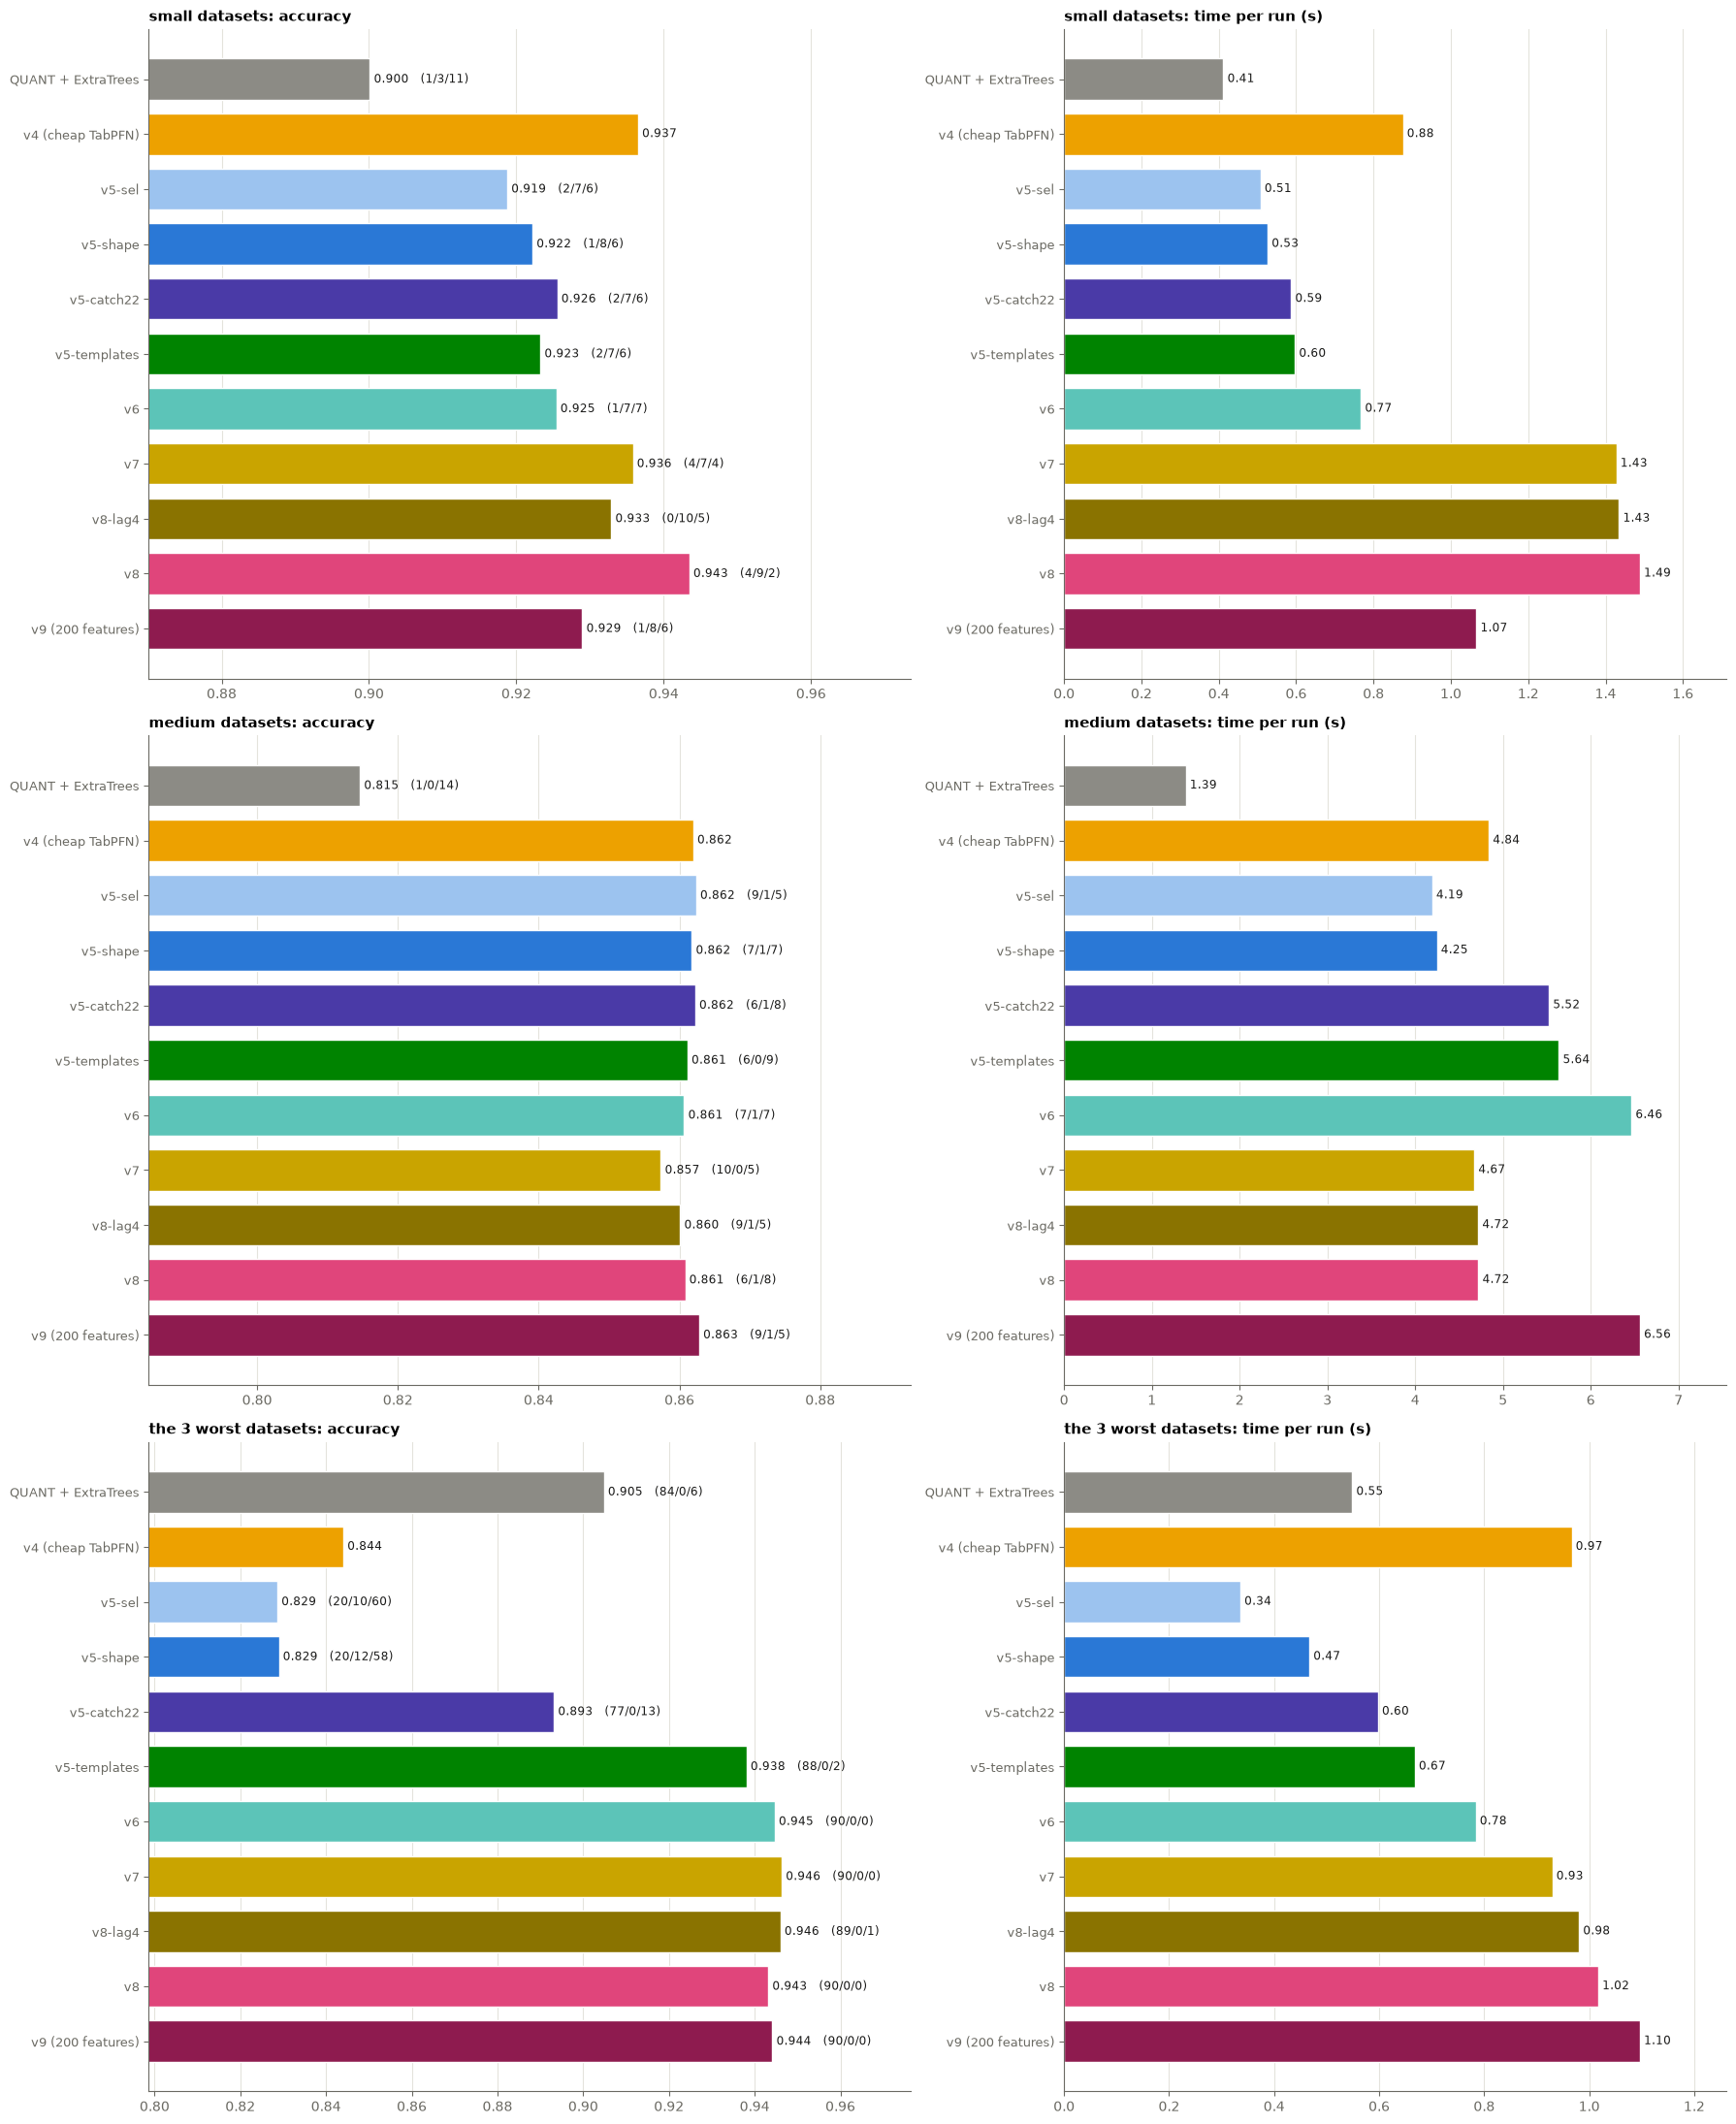

In [3]:
fig, axes = plt.subplots(3, 2, figsize=(18, 22), gridspec_kw={"width_ratios": [1.15, 1]})
y = np.arange(len(STEPS))[::-1]                  # the first version at the top
for row, lst in enumerate(LISTS):
    reference = RUNS[(lst, REFERENCE)].set_index(key)["accuracy"]
    for col, (metric, title, fmt) in enumerate([("accuracy", "accuracy", "{:.3f}"), ("total_time", "time per run (s)", "{:.2f}")]):
        ax = axes[row, col]
        values = np.array([RUNS[(lst, step)][metric].mean() for step in STEPS])
        bars = ax.barh(y, values, 0.75, color=[STEP_COLORS[s] for s in STEPS], edgecolor="white")
        labels = [fmt.format(v) for v in values]
        if metric == "accuracy":                 # + better / equal / worse runs against v4
            for k, step in enumerate(STEPS):
                if step != REFERENCE:
                    b, e, w = wdl_counts(RUNS[(lst, step)].set_index(key)["accuracy"] - reference)
                    labels[k] += f"   ({b}/{e}/{w})"
            ax.set_xlim(values.min() - 0.03, min(1.0, values.max()) + 0.03)
        else:
            ax.set_xlim(0, values.max() * 1.15)
        ax.bar_label(bars, labels=labels, padding=3, fontsize=8.5, color=TEXT)
        ax.set_yticks(y, list(STEPS), fontsize=9.5)
        ax.set_title(f"{LIST_NAMES[lst]}: {title}", loc="left")
        ax.grid(True, axis="x")
        ax.grid(False, axis="y")
fig.tight_layout()
plt.show()

Note: the accuracy axes do not start at 0, to make the differences visible; the time axes start at 0. QUANT +
ExtraTrees runs on the CPU only; its accuracy is the same on one core and on all cores (notebook 06).

The 3 worst datasets one by one (30 resamples each).

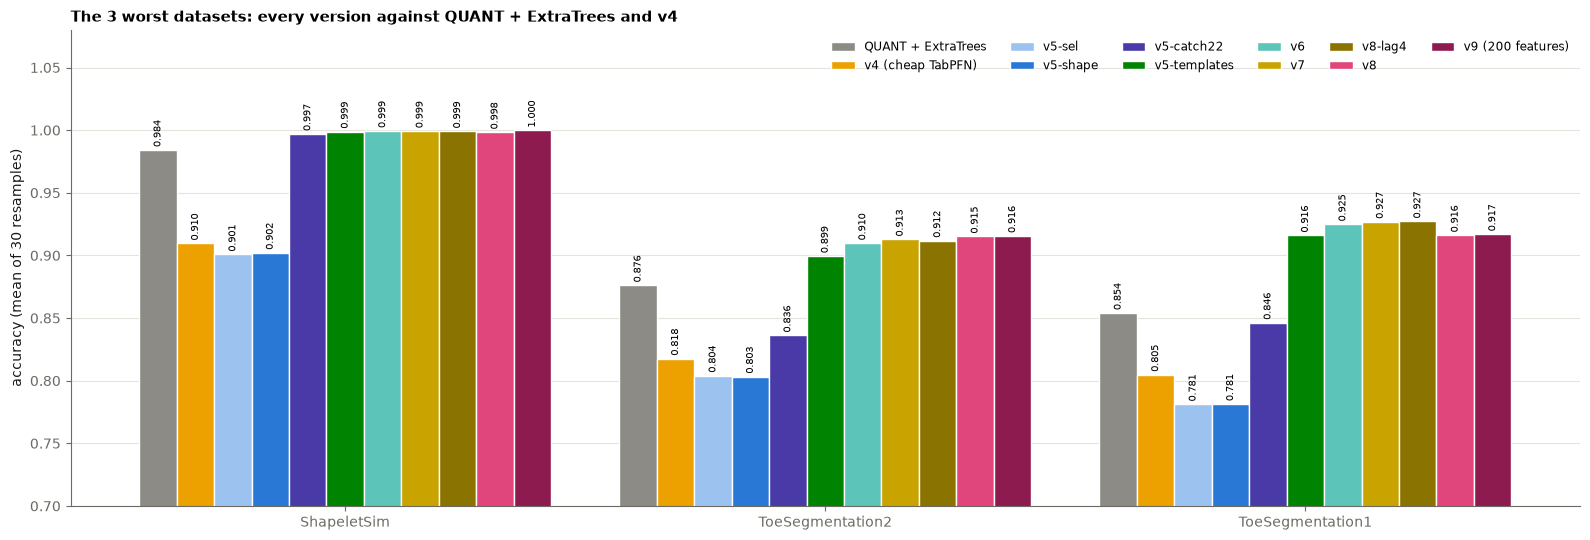

In [4]:
fig, ax = plt.subplots(figsize=(16, 5.5))
width = 0.078
for k, step in enumerate(STEPS):
    values = RUNS[("worst3", step)].groupby("dataset")["accuracy"].mean().reindex(WORST3)
    bars = ax.bar(np.arange(3) + (k - (len(STEPS) - 1) / 2) * width, values, width, color=STEP_COLORS[step],
                  edgecolor="white", label=step)
    ax.bar_label(bars, fmt="{:.3f}", padding=2, fontsize=7, rotation=90)
ax.set_xticks(range(3), WORST3)
ax.set_ylim(0.7, 1.08)
ax.set_ylabel("accuracy (mean of 30 resamples)")
ax.set_title("The 3 worst datasets: every version against QUANT + ExtraTrees and v4", loc="left")
ax.legend(loc="upper right", ncol=6, frameon=False, fontsize=8.5)
ax.grid(True, axis="y")
ax.grid(False, axis="x")
fig.tight_layout()
plt.show()

Note: the accuracy axis starts at 0.7.

The small datasets one by one with **30 resamples** (30 runs per dataset), for the versions that have them:
with 3 resamples (above) one test case of Beef is 3.3 points of accuracy. Right: the mean over the 5 datasets, with
better / equal / worse runs against v4.

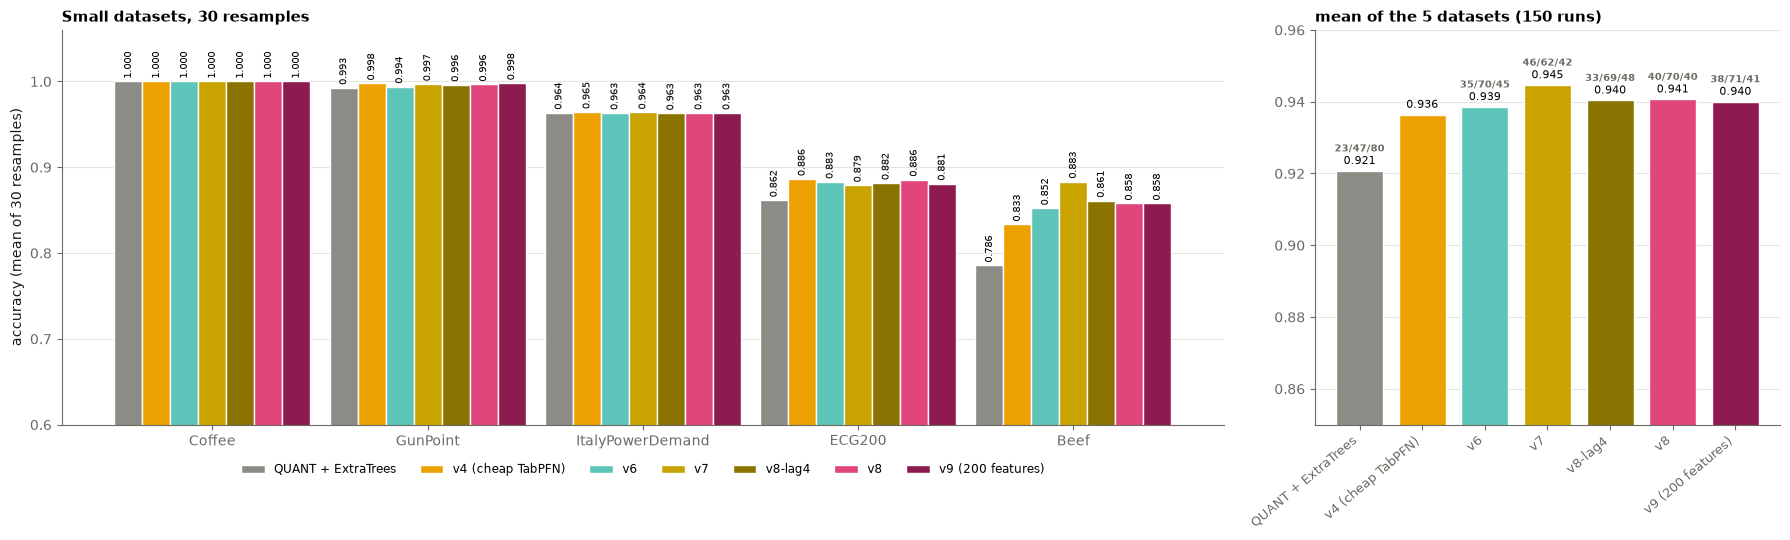

In [5]:
names = dataset_list("smoke-small")
fig, (ax, ax2) = plt.subplots(1, 2, figsize=(18, 5.5), gridspec_kw={"width_ratios": [4, 1.6]})
width = 0.13
reference = SMALL_RUNS[REFERENCE].set_index(key)["accuracy"]
for k, step in enumerate(SMALL_30):
    runs = SMALL_RUNS[step]
    values = runs.groupby("dataset")["accuracy"].mean().reindex(names)
    bars = ax.bar(np.arange(len(names)) + (k - (len(SMALL_30) - 1) / 2) * width, values, width, color=STEP_COLORS[step],
                  edgecolor="white", label=step)
    ax.bar_label(bars, fmt="{:.3f}", padding=2, fontsize=7, rotation=90)
    bar = ax2.bar(k, runs["accuracy"].mean(), 0.75, color=STEP_COLORS[step], edgecolor="white")
    ax2.bar_label(bar, fmt="{:.3f}", padding=3, fontsize=8)
    if step != REFERENCE:
        b, e, w = wdl_counts(runs.set_index(key)["accuracy"] - reference)
        ax2.annotate(f"{b}/{e}/{w}", (k, runs["accuracy"].mean()), xytext=(0, 14), textcoords="offset points",
                     ha="center", fontsize=7.5, color=MUTED, fontweight="bold")
ax.set_xticks(range(len(names)), names)
ax.set_ylim(0.6, 1.06)
ax.set_ylabel("accuracy (mean of 30 resamples)")
ax.set_title("Small datasets, 30 resamples", loc="left")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.07), ncol=7, frameon=False, fontsize=8.5)
ax2.set_xticks(range(len(SMALL_30)), SMALL_30, rotation=40, ha="right", fontsize=9)
ax2.set_ylim(0.85, 0.96)
ax2.set_title("mean of the 5 datasets (150 runs)", loc="left")
for a in (ax, ax2):
    a.grid(True, axis="y")
    a.grid(False, axis="x")
fig.tight_layout()
plt.show()

Note: the accuracy axes start at 0.6 (left) and 0.85 (right).

## 4. The funnel: candidates, relevant, kept

v5-templates (top, all candidate sources) and v6 (bottom: no shape-only view, no lag-4, the budget filled). Mean
per run: how many candidates each source produces, how many separate the classes (relevant) and how many are kept,
i.e. given to TabPFN. Sections 5 to 9 show v5-templates, the version with all candidate sources.

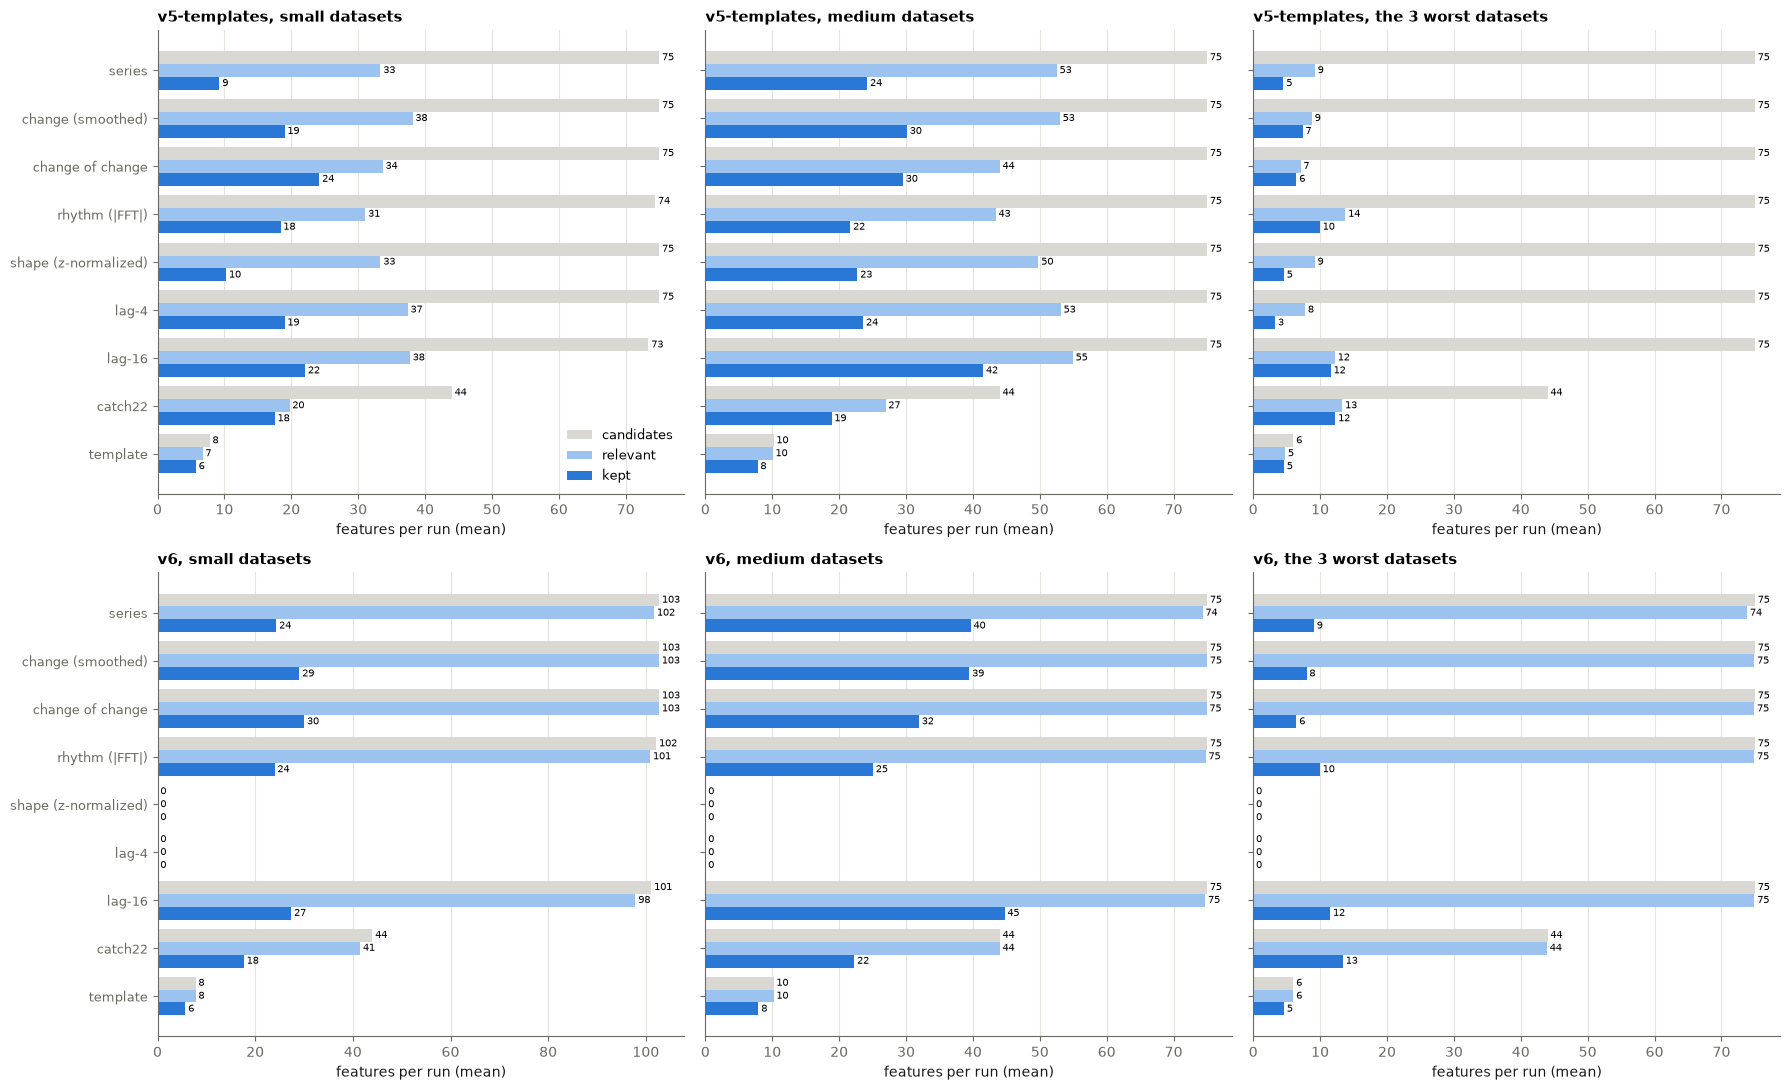

In [6]:
SOURCES = ["series", "change (smoothed)", "change of change", "rhythm (|FFT|)", "shape (z-normalized)", "lag-4", "lag-16",
           "catch22", "template"]
SOURCE_COLORS = dict(zip(SOURCES, ["#2e2380", "#4a3aa7", "#7a6dd0", "#b3abeb", "#0e8a8a", "#c94f80", "#f6c3d6",
                                   "#eda100", "#008300"]))
OUTCOMES = {"kept": BETTER, "over budget": "#9cc3ef", "near-copy": "#eda100", "irrelevant": WORSE}

def per_run(selection):
    """Mean count per run of every (source, outcome)."""
    runs = selection.groupby(key).ngroups
    return selection.groupby(["source", "outcome"])["count"].sum().unstack(fill_value=0) / runs

fig, axes = plt.subplots(2, 3, figsize=(18, 11), sharey=True)
for ax, (step, lst) in zip(axes.flat, [(step, lst) for step in ["v5-templates", "v6"] for lst in LISTS]):
    table = per_run(SELECTION[(lst, step)]).reindex(SOURCES).fillna(0)
    y = np.arange(len(SOURCES))[::-1]
    for offset, label, values, color in [(0.27, "candidates", table.sum(axis=1), "#d9d8d2"),
                                         (0.0, "relevant", table.drop(columns="irrelevant", errors="ignore").sum(axis=1), "#9cc3ef"),
                                         (-0.27, "kept", table.get("kept", 0), BETTER)]:
        bars = ax.barh(y + offset, values, 0.27, color=color, label=label)
        ax.bar_label(bars, fmt="{:.0f}", padding=2, fontsize=7.5)
    ax.set_yticks(y, SOURCES, fontsize=9)
    ax.set_xlabel("features per run (mean)")
    ax.set_title(f"{step}, {LIST_NAMES[lst]}", loc="left")
    ax.grid(True, axis="x")
    ax.grid(False, axis="y")
axes[0, 0].legend(loc="lower right", frameon=False, fontsize=9)
fig.tight_layout()
plt.show()

## 5. Why features are dropped

v5-templates: what happens to the candidates of each source, as shares. **Irrelevant**: they do not separate the
classes; **near-copy**: they repeat a feature already taken; **over budget**: relevant and new, but 250 better ones
were found; **kept**: given to TabPFN.

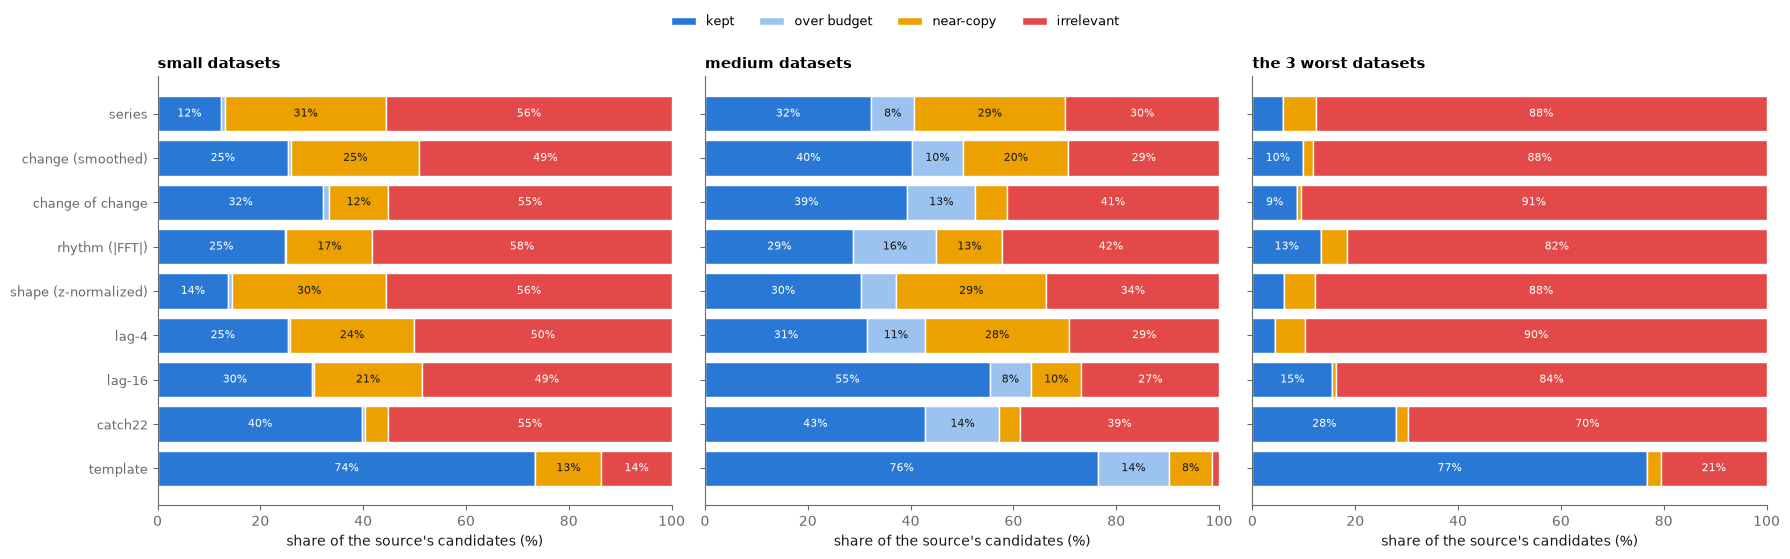

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5.5), sharey=True)
for ax, lst in zip(axes, LISTS):
    table = per_run(SELECTION[(lst, "v5-templates")]).reindex(SOURCES).fillna(0)
    shares = 100 * table.div(table.sum(axis=1), axis=0)
    y = np.arange(len(SOURCES))[::-1]
    left = np.zeros(len(SOURCES))
    for outcome, color in OUTCOMES.items():
        values = shares.get(outcome, pd.Series(0, index=SOURCES)).values
        bars = ax.barh(y, values, left=left, color=color, edgecolor="white", label=outcome if ax is axes[0] else None)
        ax.bar_label(bars, labels=[f"{v:.0f}%" if v >= 8 else "" for v in values], label_type="center", fontsize=8,
                     color="white" if outcome in ("kept", "irrelevant") else TEXT)
        left += values
    ax.set_yticks(y, SOURCES, fontsize=9)
    ax.set_xlim(0, 100)
    ax.set_xlabel("share of the source's candidates (%)")
    ax.set_title(LIST_NAMES[lst], loc="left")
    ax.grid(False)
fig.legend(loc="upper center", ncol=4, frameon=False, fontsize=9, bbox_to_anchor=(0.5, 1.02))
fig.tight_layout(rect=(0, 0, 1, 0.95))
plt.show()

## 6. Which kinds and piece sizes are kept how often

The interval features of v5-templates: for every source and kind (rows) and piece size (columns), the share of the
candidates that are kept. Dark cells are kept often; light cells are produced but almost never used.

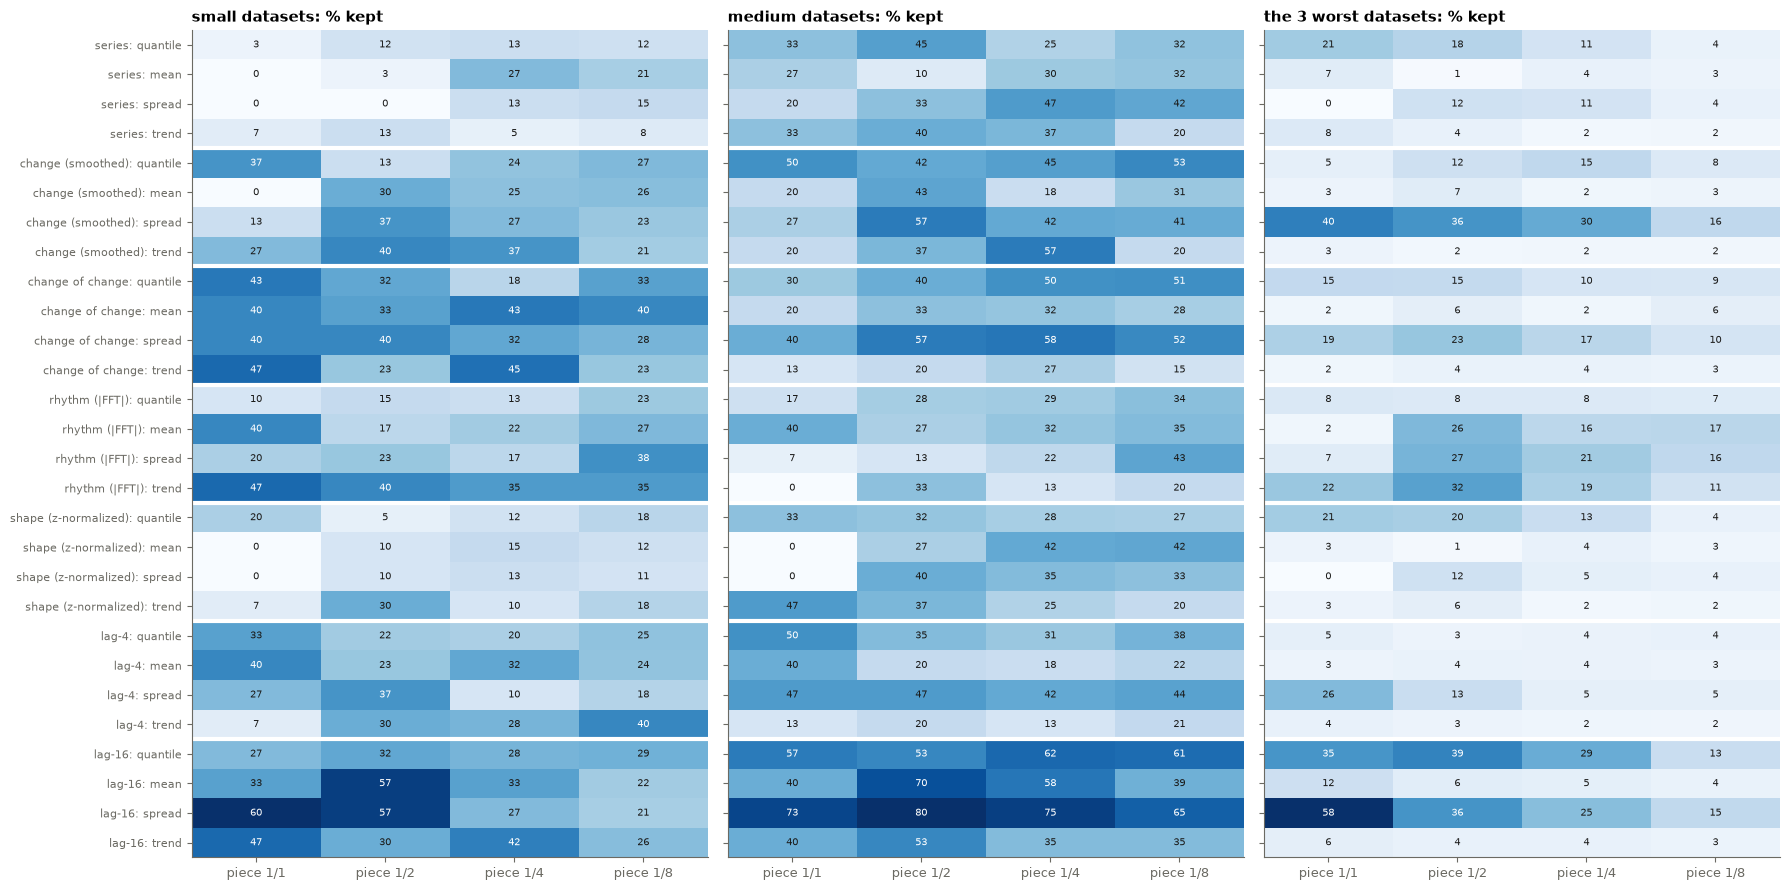

In [8]:
LEVELS = ["1/1", "1/2", "1/4", "1/8"]
KINDS = ["quantile", "mean", "spread", "trend"]
INTERVAL_SOURCES = SOURCES[:7]
fig, axes = plt.subplots(1, 3, figsize=(18, 9), sharey=True)
for ax, lst in zip(axes, LISTS):
    s = SELECTION[(lst, "v5-templates")]
    s = s[s["source"].isin(INTERVAL_SOURCES)]
    produced = s.groupby(["source", "kind", "level"])["count"].sum()
    kept = s[s["outcome"] == "kept"].groupby(["source", "kind", "level"])["count"].sum()
    rows = [(src, kind) for src in INTERVAL_SOURCES for kind in KINDS]
    share = np.array([[100 * kept.get((src, kind, lv), 0) / produced[(src, kind, lv)] if (src, kind, lv) in produced else np.nan
                       for lv in LEVELS] for src, kind in rows])
    ax.imshow(share, cmap="Blues", vmin=0, vmax=max(1, np.nanmax(share)), aspect="auto")
    for r in range(len(rows)):
        for c in range(len(LEVELS)):
            if not np.isnan(share[r, c]):
                ax.text(c, r, f"{share[r, c]:.0f}", ha="center", va="center", fontsize=7.5,
                        color="white" if share[r, c] > 0.6 * np.nanmax(share) else TEXT)
    for r in range(len(KINDS), len(rows), len(KINDS)):
        ax.axhline(r - 0.5, color="white", linewidth=3)
    ax.set_xticks(range(len(LEVELS)), [f"piece {lv}" for lv in LEVELS], fontsize=9)
    ax.set_yticks(range(len(rows)), [f"{src}: {kind}" for src, kind in rows], fontsize=8)
    ax.set_title(f"{LIST_NAMES[lst]}: % kept", loc="left")
    ax.grid(False)
fig.tight_layout()
plt.show()

Note: piece 1/1 is the whole series, 1/8 the smallest pieces (an eighth of the series).

## 7. Near-copies: which source duplicates which

For the candidates dropped as near-copies: the source of the dropped feature (rows) against the source of the
feature it repeats (columns), as a share of the row. All three lists of v5-templates together.

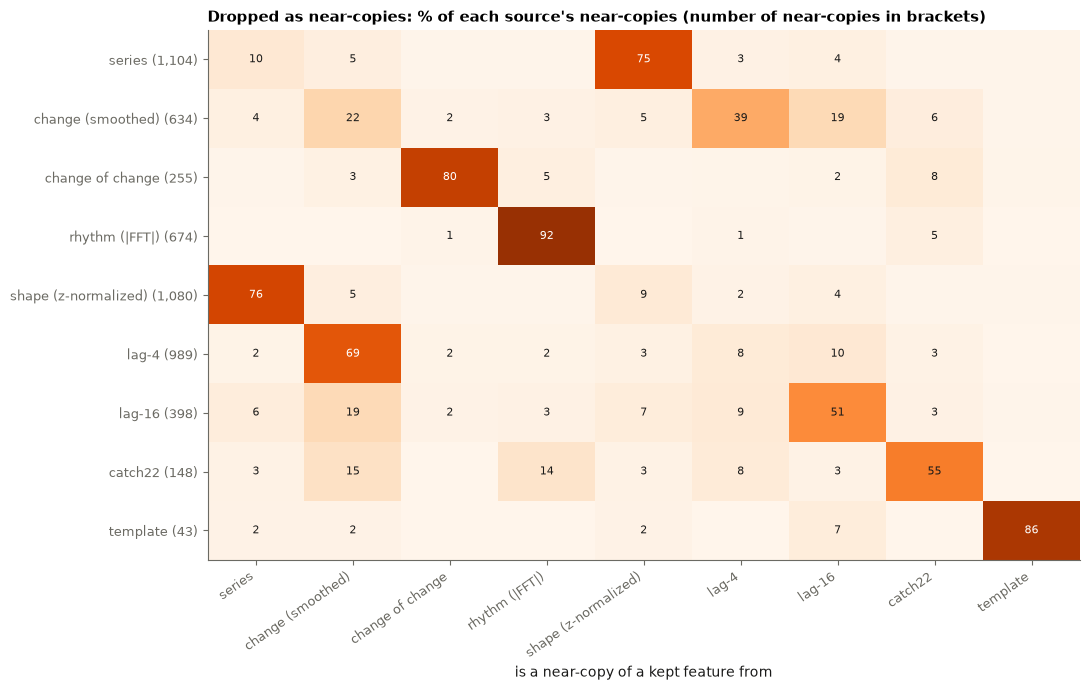

In [9]:
s = pd.concat([SELECTION[(lst, "v5-templates")] for lst in LISTS])
copies = s[s["outcome"] == "near-copy"].groupby(["source", "copy_of"])["count"].sum().unstack(fill_value=0)
copies = copies.reindex(index=SOURCES, columns=SOURCES).fillna(0)
shares = 100 * copies.div(copies.sum(axis=1).replace(0, np.nan), axis=0)
fig, ax = plt.subplots(figsize=(11, 7))
ax.imshow(shares.values, cmap="Oranges", vmin=0, vmax=100, aspect="auto")
for r in range(len(SOURCES)):
    for c in range(len(SOURCES)):
        v = shares.values[r, c]
        if v >= 1:
            ax.text(c, r, f"{v:.0f}", ha="center", va="center", fontsize=8, color="white" if v > 60 else TEXT)
ax.set_xticks(range(len(SOURCES)), SOURCES, rotation=35, ha="right", fontsize=9)
ax.set_yticks(range(len(SOURCES)), [f"{src} ({copies.loc[src].sum():,.0f})" for src in SOURCES], fontsize=9)
ax.set_xlabel("is a near-copy of a kept feature from")
ax.set_title("Dropped as near-copies: % of each source's near-copies (number of near-copies in brackets)", loc="left")
ax.grid(False)
fig.tight_layout()
plt.show()

## 8. catch22: which of its features are kept

The share of runs in which each catch22 feature (of the series and of its change) is kept, all three lists of the
last step together.

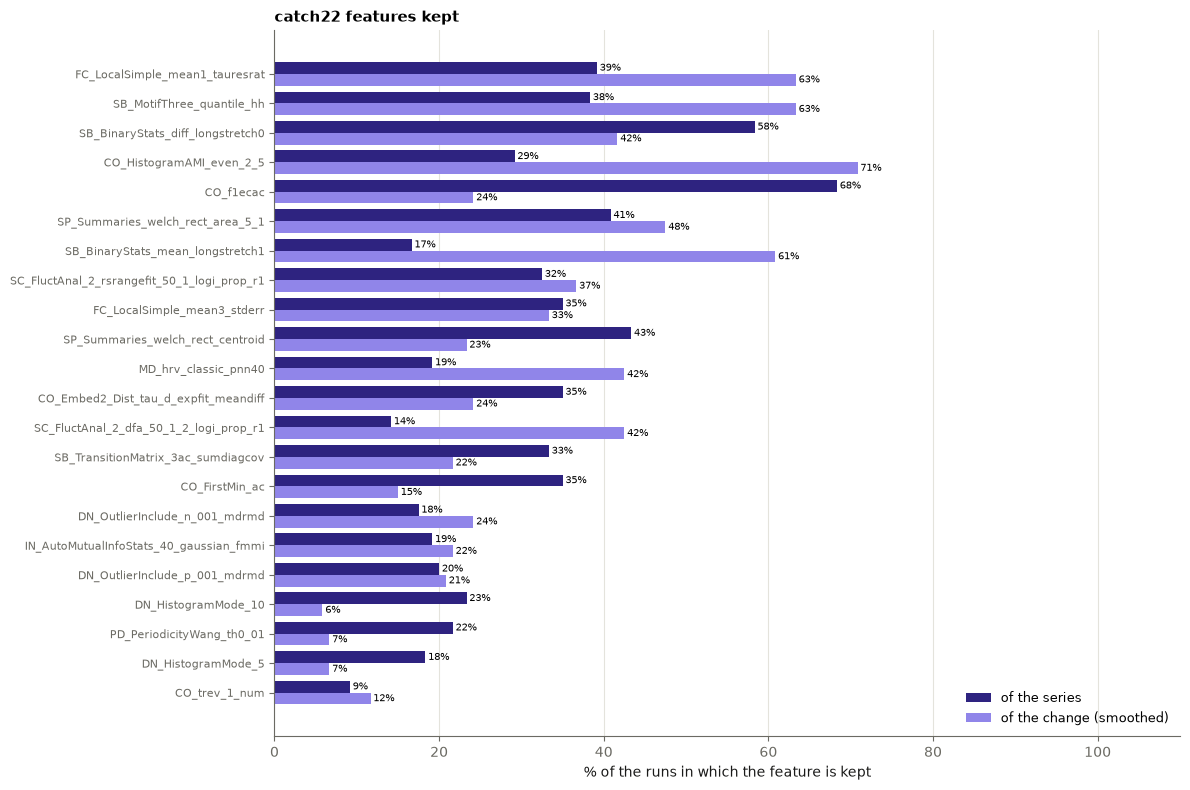

In [10]:
c22 = s[s["source"] == "catch22"].copy()
c22["feature"] = c22["kind"].str.replace(r" \(.*\)$", "", regex=True)
c22["of"] = c22["kind"].str.extract(r"\((.*)\)$", expand=False)
kept_share = (c22.assign(kept=(c22["outcome"] == "kept") * c22["count"])
              .groupby(["feature", "of"])[["kept", "count"]].sum())
kept_share = (100 * kept_share["kept"] / kept_share["count"]).unstack()
order = kept_share.mean(axis=1).sort_values().index
fig, ax = plt.subplots(figsize=(12, 8))
y = np.arange(len(order))
for offset, of, color in [(0.2, "series", "#2e2380"), (-0.2, "change (smoothed)", "#9085e9")]:
    bars = ax.barh(y + offset, kept_share.loc[order, of], 0.4, color=color, label=f"of the {of}")
    ax.bar_label(bars, fmt="{:.0f}%", padding=2, fontsize=7.5)
ax.set_yticks(y, order, fontsize=8)
ax.set_xlim(0, 110)
ax.set_xlabel("% of the runs in which the feature is kept")
ax.set_title("catch22 features kept", loc="left")
ax.legend(loc="lower right", frameon=False, fontsize=9)
ax.grid(True, axis="x")
ax.grid(False, axis="y")
fig.tight_layout()
plt.show()

## 9. Pattern templates: how often they are kept

Per dataset (v5-templates): the share of its templates that are kept. In brackets: the number of classes and of
templates per run (at least one per class). The 3 worst datasets are in bold.

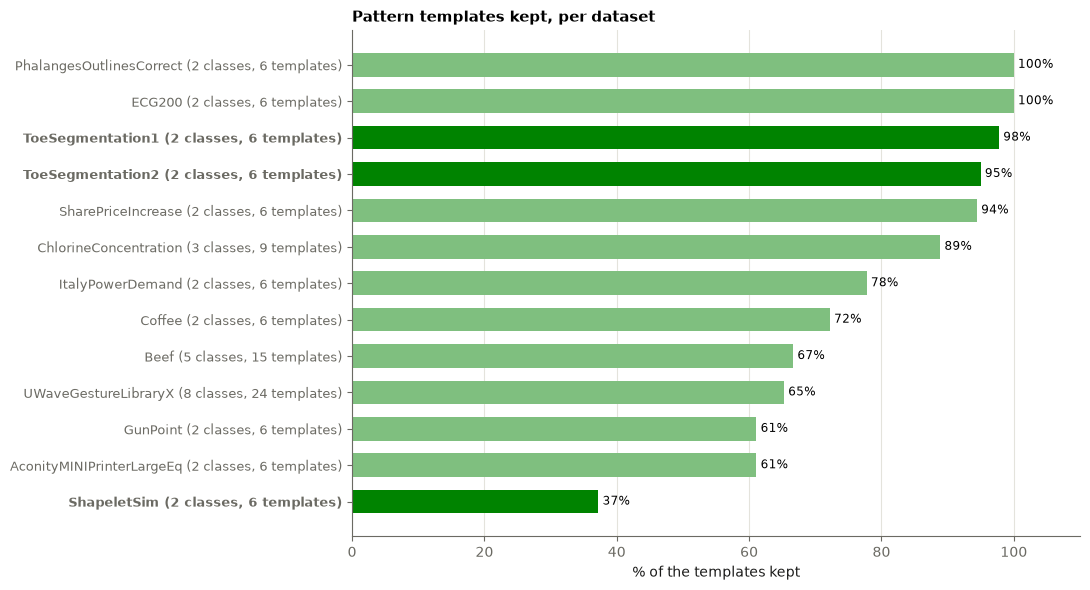

In [11]:
t = s[s["source"] == "template"]
per_dataset = t.assign(kept=(t["outcome"] == "kept") * t["count"]).groupby("dataset")[["kept", "count"]].sum()
per_dataset["share"] = 100 * per_dataset["kept"] / per_dataset["count"]
per_dataset["classes"] = [len(read_split(name, "TRAIN")[2]) for name in per_dataset.index]
per_dataset["per run"] = per_dataset["count"] / t.groupby("dataset")["resample"].nunique()
per_dataset = per_dataset.sort_values("share")
fig, ax = plt.subplots(figsize=(11, 6))
y = np.arange(len(per_dataset))
bars = ax.barh(y, per_dataset["share"], 0.65, color=[STEP_COLORS["v5-templates"] if n in WORST3 else "#7fbf7f" for n in per_dataset.index])
ax.bar_label(bars, fmt="{:.0f}%", padding=3, fontsize=8.5)
ax.set_yticks(y, [f"{n} ({r['classes']:.0f} classes, {r['per run']:.0f} templates)" for n, r in per_dataset.iterrows()], fontsize=9)
for label in ax.get_yticklabels():
    if label.get_text().split(" (")[0] in WORST3:
        label.set_fontweight("bold")
ax.set_xlim(0, 110)
ax.set_xlabel("% of the templates kept")
ax.set_title("Pattern templates kept, per dataset", loc="left")
ax.grid(True, axis="x")
ax.grid(False, axis="y")
fig.tight_layout()
plt.show()

## 10. Which lags each dataset uses (v8)

With `--lags auto` (v8) every lag-d view of the ladder is a candidate, and the selection decides per dataset which are
used. Per dataset (rows; series length in brackets): the share of the kept features that come from each lag view
(columns), the mean over its runs. Empty cells: the series is too short for that lag.

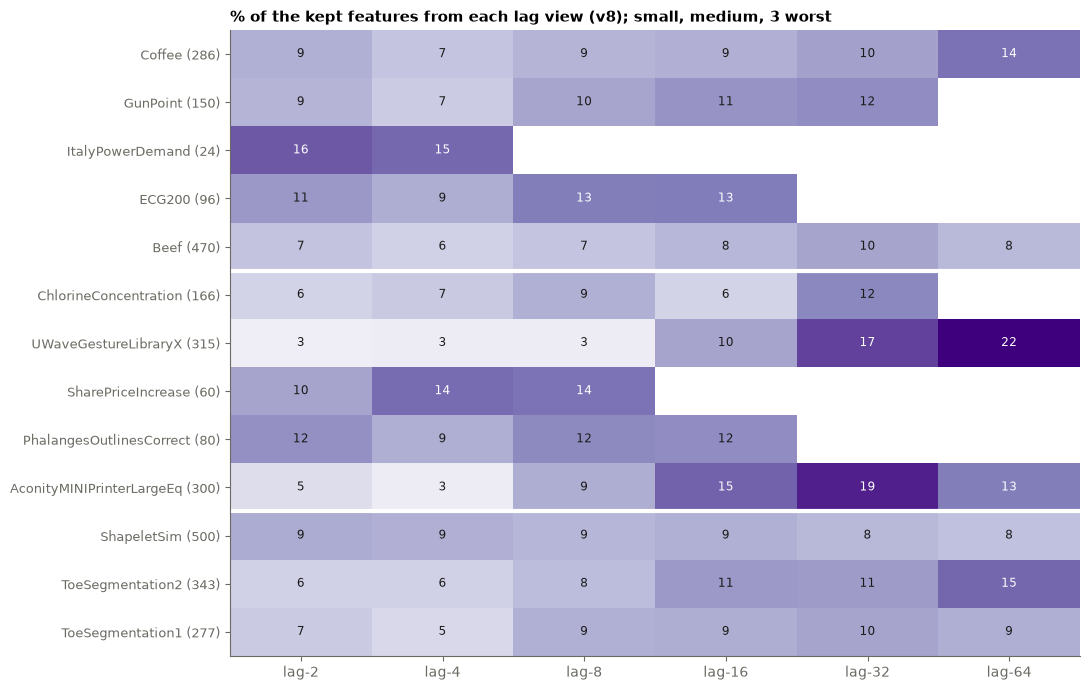

In [12]:
LAG_VIEWS = [f"lag-{2 ** k}" for k in range(1, 7)]
s17 = pd.concat([SELECTION[(lst, "v8")] for lst in LISTS])
kept = s17[s17["outcome"].str.startswith("kept")]
runs = s17.groupby("dataset")["resample"].nunique()
per_view = kept.groupby(["dataset", "source"])["count"].sum().unstack(fill_value=0).div(runs, axis=0)
share = 100 * per_view.div(per_view.sum(axis=1), axis=0)
offered = s17.groupby(["dataset", "source"])["count"].sum().unstack()          # NaN: the view was not offered
names = [n for lst in LISTS for n in dataset_list(lst)]
table = share.reindex(index=names, columns=LAG_VIEWS).where(offered.reindex(index=names, columns=LAG_VIEWS).notna())
fig, ax = plt.subplots(figsize=(11, 7))
ax.imshow(table.values, cmap="Purples", vmin=0, vmax=np.nanmax(table.values), aspect="auto")
for r in range(len(names)):
    for c in range(len(LAG_VIEWS)):
        v = table.values[r, c]
        if not np.isnan(v):
            ax.text(c, r, f"{v:.0f}", ha="center", va="center", fontsize=8.5,
                    color="white" if v > 0.6 * np.nanmax(table.values) else TEXT)
ax.set_xticks(range(len(LAG_VIEWS)), LAG_VIEWS)
ax.set_yticks(range(len(names)), [f"{n} ({read_split(n, 'TRAIN')[1]})" for n in names], fontsize=9)
for r in [len(dataset_list("smoke-small")), len(dataset_list("smoke-small")) + len(dataset_list("smoke-medium"))]:
    ax.axhline(r - 0.5, color="white", linewidth=3)
ax.set_title("% of the kept features from each lag view (v8); small, medium, 3 worst", loc="left")
ax.grid(False)
fig.tight_layout()
plt.show()

## 11. v8 on all 142 datasets, and its 10 worst

v8 was run on the paper's full benchmark (142 datasets x 30 resamples, `experiments.md`, v8), like v4 and v9
(notebook 06). Below: v8 against QUANT + ExtraTrees and v4 on all 142 datasets, and the change on every dataset
against QUANT + ExtraTrees, sorted; the 10 datasets where v8 loses most are marked.

v8 vs QUANT + ExtraTrees, 142 datasets: mean accuracy 0.8827 vs 0.8548; better / equal / worse (122, 6, 14); Wilcoxon p = 1.7e-19
v8 vs v4 (cheap TabPFN), 142 datasets: mean accuracy 0.8827 vs 0.8733; better / equal / worse (97, 5, 40); Wilcoxon p = 3.1e-10
v9 (200 features) vs v8, 142 datasets: mean accuracy 0.8849 vs 0.8827; better / equal / worse (88, 5, 49); Wilcoxon p = 3.5e-05
v8: 5.0 hours for 4260 runs


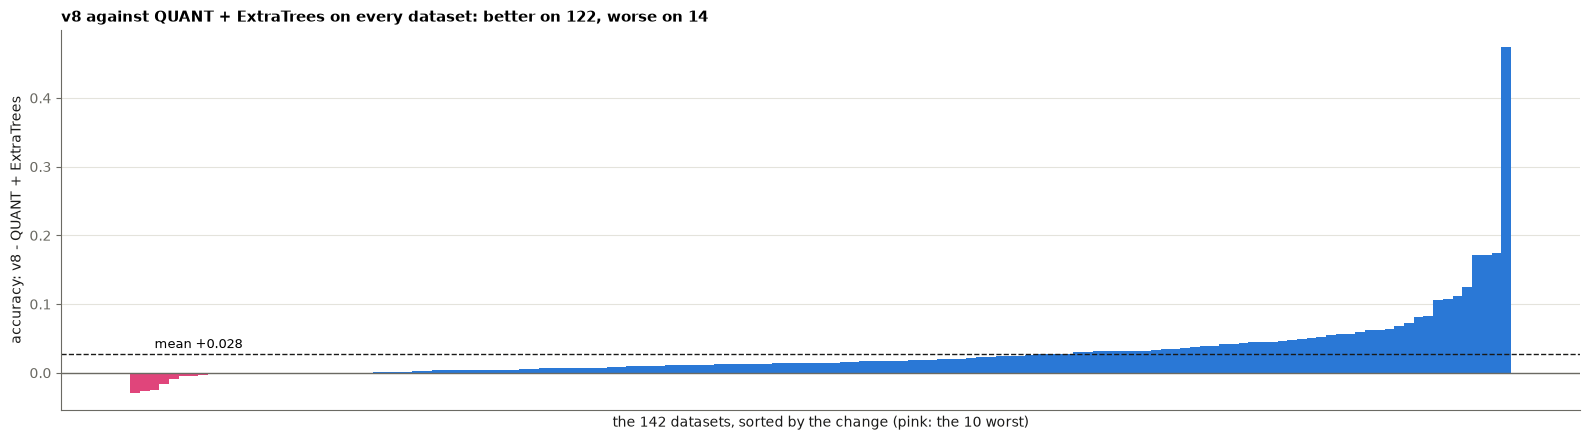

In [13]:
from scipy import stats
from common import signed

v8_full = load("v8_tabpfn-e2f250_ucr142_allcores-gpu.csv")              # v8 on all 142 datasets x 30 resamples
MEAN142 = pd.DataFrame({name: runs.groupby("dataset")["accuracy"].mean() for name, runs in
                        [("QUANT + ExtraTrees", full_runs["QUANT + ExtraTrees"]), ("v4 (cheap TabPFN)", full_runs["v4 (cheap TabPFN)"]),
                         ("v8", v8_full), ("v9 (200 features)", full_runs["v9 (200 features)"])]})
for a, b in [("v8", "QUANT + ExtraTrees"), ("v8", "v4 (cheap TabPFN)"), ("v9 (200 features)", "v8")]:
    x = MEAN142[a] - MEAN142[b]
    print(f"{a} vs {b}, 142 datasets: mean accuracy {MEAN142[a].mean():.4f} vs {MEAN142[b].mean():.4f}; "
          f"better / equal / worse {wdl_counts(x)}; Wilcoxon p = {stats.wilcoxon(MEAN142[a], MEAN142[b]).pvalue:.1e}")
print(f"v8: {v8_full['total_time'].sum() / 3600:.1f} hours for {len(v8_full)} runs")

WORST10 = dataset_list("worst10")                # the 10 datasets where v8 loses most to QUANT + ExtraTrees
change = (MEAN142["v8"] - MEAN142["QUANT + ExtraTrees"]).sort_values()
fig, ax = plt.subplots(figsize=(16, 4.5))
ax.bar(range(len(change)), change, 1.0,
       color=[STEP_COLORS["v8"] if n in WORST10 else BETTER if x > 1e-12 else WORSE if x < -1e-12 else EQUAL
              for n, x in change.items()])
ax.axhline(0, color=MUTED, linewidth=1)
ax.axhline(change.mean(), color=TEXT, linewidth=1, linestyle="--")
ax.annotate(f"mean {signed(change.mean())}", (2, change.mean()), xytext=(0, 4), textcoords="offset points", fontsize=9)
ax.set_xticks([])
ax.set_xlabel("the 142 datasets, sorted by the change (pink: the 10 worst)")
ax.set_ylabel("accuracy: v8 - QUANT + ExtraTrees")
ax.set_title(f"v8 against QUANT + ExtraTrees on every dataset: better on {(change > 1e-12).sum()}, "
             f"worse on {(change < -1e-12).sum()}", loc="left")
fig.tight_layout()
plt.show()

v8 is less accurate than QUANT + ExtraTrees on 14 of the 142 datasets, by at most 0.029. Three diagnostic runs on
the 10 where it loses most (`improvedQuant/dataSetLists/worst10.txt`, 30 resamples each; `experiments.md`, v3 and
v8) separate the possible causes:

- **TabPFN on QUANT's full feature set** (212 to 5,647 features, all given to TabPFN, which itself looks at no more
  than 768 per pass): is TabPFN the weaker classifier on these datasets?
- **ExtraTrees on v8's features** (the same 250 features, the original classifier): are the features or TabPFN the
  cause?
- **v8 without the fill** (only the features that pass the relevance check, no weaker features to fill the budget):
  does the fill add noise?

**v9 (200 features)** is shown next to them, from its full run: it adds the median and inner quantiles of QUANT's
views, which this diagnosis pointed to. Left: the mean over the 10 datasets. Right: the change against QUANT +
ExtraTrees on each dataset (with its training cases, classes and series length).

v8's features with TabPFN in the diagnostic run = the full run: True


the 10 datasets: v8 - QUANT + ExtraTrees: Herring -0.029, Colposcopy -0.026, MoteStrain -0.024, Lightning2 -0.017, DistalPhalanxOutlineAgeGroup -0.008, Chinatown -0.005, InsectEPGSmallTrain -0.004, InsectWingbeatSound -0.003, Symbols -0.002, Covid3MonthDiscrete -0.002


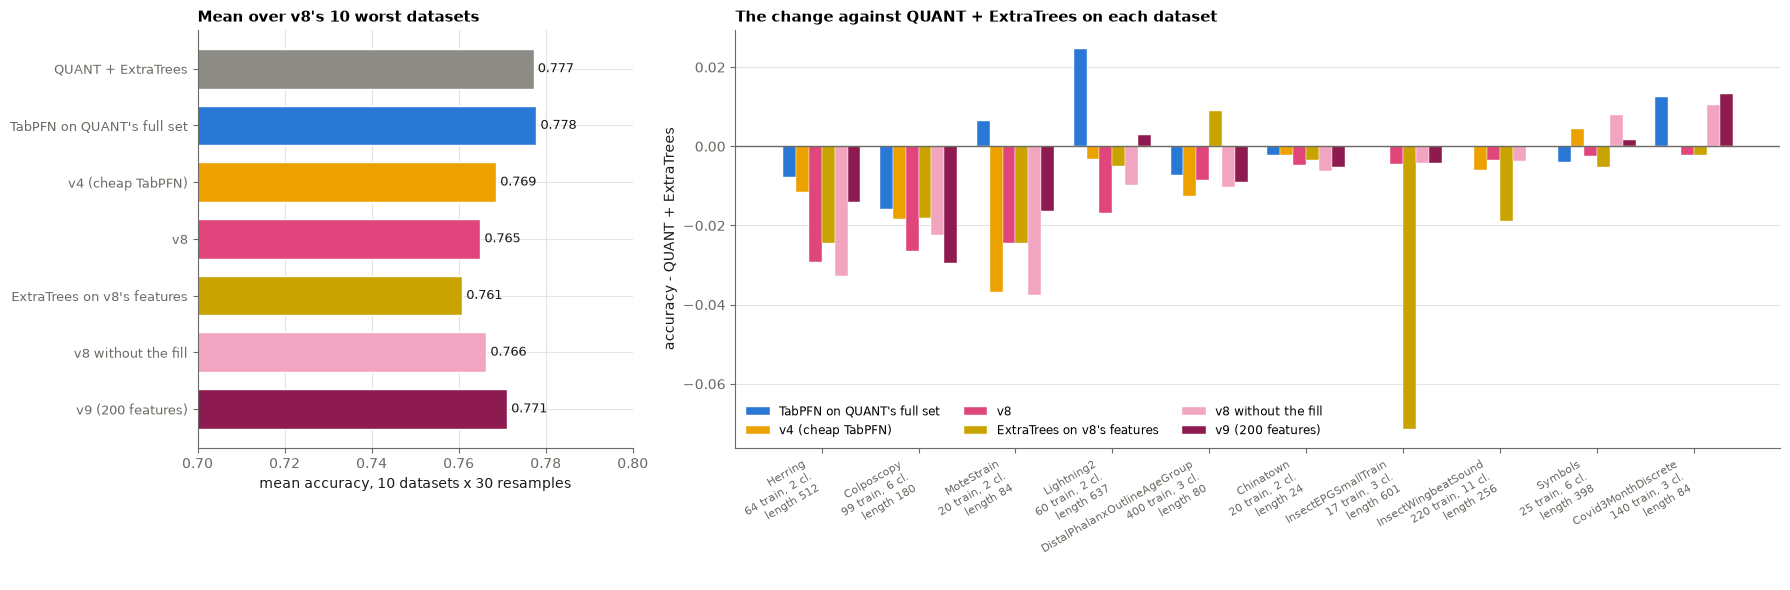

In [14]:
DIAGNOSTIC = {                                                         # name -> runs (the 10 datasets are picked below)
    "QUANT + ExtraTrees": full_runs["QUANT + ExtraTrees"],
    "TabPFN on QUANT's full set": load("v3-quant_tabpfn-e2fall-cache_worst10_allcores-gpu.csv"),
    "v4 (cheap TabPFN)": full_runs["v4 (cheap TabPFN)"],
    "v8": v8_full,
    "ExtraTrees on v8's features": None,
    "v8 without the fill": load("v8-nofill_tabpfn-e2f250_worst10_allcores-gpu.csv"),
    "v9 (200 features)": full_runs["v9 (200 features)"],
}
both = load("v8_tabpfn-e2f250-and-extratrees_worst10_allcores-gpu.csv")    # v8's features, 2 classifiers
DIAGNOSTIC["ExtraTrees on v8's features"] = both[both["classifier"] == "extratrees"]
DIAGNOSTIC_COLORS = {"QUANT + ExtraTrees": STEP_COLORS["QUANT + ExtraTrees"], "TabPFN on QUANT's full set": "#2a78d6",
                     "v4 (cheap TabPFN)": STEP_COLORS["v4 (cheap TabPFN)"], "v8": STEP_COLORS["v8"],
                     "ExtraTrees on v8's features": "#c9a400", "v8 without the fill": "#f2a5c0",
                     "v9 (200 features)": STEP_COLORS["v9 (200 features)"]}
worst = pd.DataFrame({name: runs[runs["dataset"].isin(WORST10)].groupby("dataset")["accuracy"].mean()
                      for name, runs in DIAGNOSTIC.items()}).loc[WORST10]
tabpfn_v8 = both[both["classifier"] == "tabpfn"].groupby("dataset")["accuracy"].mean()
print(f"v8's features with TabPFN in the diagnostic run = the full run: {np.allclose(tabpfn_v8[WORST10], worst['v8'])}")
print("the 10 datasets: v8 - QUANT + ExtraTrees:",
      ", ".join(f"{n} {signed(x)}" for n, x in (worst["v8"] - worst["QUANT + ExtraTrees"]).items()))

fig, axes = plt.subplots(1, 2, figsize=(18, 6), gridspec_kw={"width_ratios": [1, 2.4]})
ax = axes[0]
means = worst.mean()
y = np.arange(len(means))[::-1]
bars = ax.barh(y, means, 0.7, color=[DIAGNOSTIC_COLORS[n] for n in means.index], edgecolor="white")
ax.bar_label(bars, fmt="{:.3f}", padding=3, fontsize=9.5, color=TEXT)
ax.set_yticks(y, list(means.index), fontsize=9.5)
ax.set_xlim(0.70, 0.80)
ax.set_xlabel("mean accuracy, 10 datasets x 30 resamples")
ax.set_title("Mean over v8's 10 worst datasets", loc="left")

ax = axes[1]
diff = worst.drop(columns="QUANT + ExtraTrees").sub(worst["QUANT + ExtraTrees"], axis=0)
width = 0.8 / diff.shape[1]
for k, name in enumerate(diff.columns):
    ax.bar(np.arange(len(WORST10)) + (k - (diff.shape[1] - 1) / 2) * width, diff[name], width,
           color=DIAGNOSTIC_COLORS[name], edgecolor="white", linewidth=0.3, label=name)
ax.axhline(0, color=MUTED, linewidth=1)
info = {name: read_split(name, "TRAIN") for name in WORST10}               # (cases, length, classes)
ax.set_xticks(range(len(WORST10)), [f"{name}\n{n} train, {len(c)} cl.\nlength {L}" for name, (n, L, c) in info.items()],
              fontsize=8, rotation=30, ha="right")
ax.set_ylabel("accuracy - QUANT + ExtraTrees")
ax.set_title("The change against QUANT + ExtraTrees on each dataset", loc="left")
ax.legend(loc="lower left", ncol=3, frameon=False, fontsize=8.5)
for a in axes:
    a.grid(True, axis="x" if a is axes[0] else "y")
fig.tight_layout()
plt.show()

Note: the accuracy axis on the left starts at 0.70, to make the differences visible.

- **The classifier is not the cause.** On QUANT's full feature set TabPFN is as accurate as ExtraTrees (0.778
  against 0.777), and on v8's 250 features ExtraTrees is no better than TabPFN (0.761 against 0.765; it loses most
  on InsectEPGSmallTrain, 17 training cases, where TabPFN on the same features is almost perfect).
- **The fill is not the cause either:** without the weaker features v8 gets 0.766, the same as with them.
- **The cause is the feature set:** with the same classifier, v8's 250 features give 0.765 and QUANT's full set
  0.778 (on Herring, MoteStrain and Lightning2, three of the four largest losses, TabPFN on QUANT's full set loses
  little or gains). 6 of the 10 datasets have 64 training cases or fewer and 8 fewer than 150 (17 for
  InsectEPGSmallTrain, 20 for MoteStrain and Chinatown); with so few cases the relevance check and the ExtraTrees
  importance cannot tell reliably which of the candidates carry the class, so a budget of 250 leaves some of them
  out, while QUANT + ExtraTrees keeps every feature and averages over hundreds of trees. v4, which picks its 200
  from QUANT-style features only, is in between (0.769).
- **Which of QUANT's features?** A scratch test (`experiments.md`, v9) removed each kind of feature QUANT has and v8
  does not from QUANT + TabPFN, and added each to v8's candidates: only the median and inner quantiles helped
  TabPFN; the 1/32 pieces, the shifted pieces and the quantiles minus the piece's mean did not.
- **v9 halves the gap** (0.771, against 0.765 for v8 and 0.777 for QUANT + ExtraTrees) with a fifth of QUANT's
  quantiles, median kept: Lightning2 and Symbols are now gains, Herring loses -0.014 instead of -0.029; Colposcopy
  stays the largest loss (-0.029).

## 12. From v8 to v9: time, QUANT's features, and the budget

v9 is v8 with four changes; this section shows the tests behind them (`experiments.md`, v8 and v9;
`improvedQuant/features/feature_test.py` for the feature tests):

1. **Time.** Where v8's 5 hours go, by phase, next to v4 and v9 (from the full runs), and a test of the depth of the
   fill rounds: v8 with the fill rounds stopped at pieces of 1/16 instead of 1/32 (`--supervised_max_depth 5`), on
   the 15 datasets whose fill rounds reached 1/32 in v8's full run (`deep6.txt`), 10 resamples, against v8's full
   run on the same splits. (The other speed fix, catch22 and the templates computed once for all fill rounds, gives
   identical results and is always on.)
2. **Which of QUANT's features does TabPFN need?** QUANT has four kinds of interval features that v8 does not: pieces
   down to 1/32, shifted pieces, dense quantiles (one per 4 points, the median and the inner quantiles among them) and
   quantiles minus the piece's mean. On the 7 datasets of section 11 where v8 loses significantly (`worst7.txt`, 10
   resamples): QUANT + TabPFN (2 passes x 250 features, picked as v4) with one kind removed or changed, and the
   supervised extractor with v9's settings with one kind added to the candidates of QUANT's four views.
3. **The check on the other lists:** v9's settings with min and max (as v8) or a fifth of QUANT's quantiles, median
   kept (as v9), on the 3 worst datasets and the small list (30 resamples) and the medium list (10); on
   ChlorineConcentration and UWaveGestureLibraryX also with the ANOVA order instead of the ExtraTrees importance.
4. **200 features instead of 250** on the small and medium lists, with QUANT + TabPFN at the same 2 x 200 (QUANT's
   own features picked as v4) next to them; v9 with 200 features comes from its full run (the same command).

hours by phase: {'v4 (cheap TabPFN)': {'features, training data': 0.18, 'features, test data': 0.24, 'TabPFN (fit + predict)': 2.6}, 'v8': {'features, training data': 2.13, 'features, test data': 0.83, 'TabPFN (fit + predict)': 2.03}, 'v9 (200 features)': {'features, training data': 1.75, 'features, test data': 0.81, 'TabPFN (fit + predict)': 2.11}}
fill rounds down to 1/16 vs 1/32 (v8), 15 datasets x 10 resamples: accuracy 0.9272 vs 0.9262, better / equal / worse (39, 75, 36), Wilcoxon p = 0.52; time per run 4.2 s vs 8.4 s


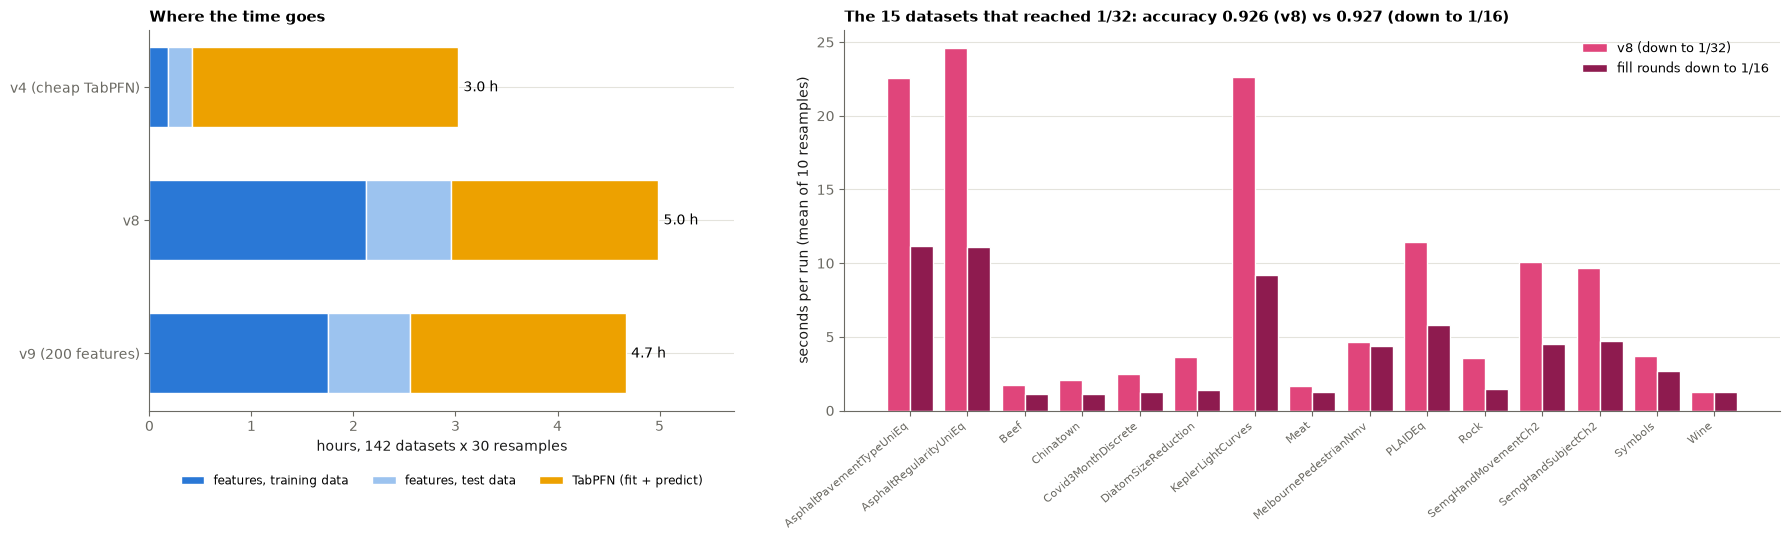

In [15]:
PHASES = {"features, training data": ["time_transform_train", "time_lag_train", "time_extra_train"],
          "features, test data": ["time_transform_test", "time_lag_test", "time_extra_test"],
          "TabPFN (fit + predict)": ["time_fit", "time_predict"]}
PHASE_COLORS = ["#2a78d6", "#9cc3ef", "#eda100"]
FULL = {"v4 (cheap TabPFN)": full_runs["v4 (cheap TabPFN)"], "v8": v8_full, "v9 (200 features)": full_runs["v9 (200 features)"]}
hours = pd.DataFrame({name: {phase: runs[cols].sum().sum() / 3600 for phase, cols in PHASES.items()}
                      for name, runs in FULL.items()}).T
print("hours by phase:", hours.round(2).to_dict("index"))

DEEP6 = dataset_list("deep6")                    # the 15 datasets whose fill rounds reached 1/32 in v8's full run
depth5 = load("v8-depth5_tabpfn-e2f250_deep6_allcores-gpu.csv").set_index(key)
v8_deep = v8_full.set_index(key).loc[depth5.index]
x = depth5["accuracy"] - v8_deep["accuracy"]
print(f"fill rounds down to 1/16 vs 1/32 (v8), 15 datasets x 10 resamples: accuracy {depth5['accuracy'].mean():.4f} vs "
      f"{v8_deep['accuracy'].mean():.4f}, better / equal / worse {wdl_counts(x)}, Wilcoxon p = {stats.wilcoxon(x).pvalue:.2f}; "
      f"time per run {depth5['total_time'].mean():.1f} s vs {v8_deep['total_time'].mean():.1f} s")

fig, axes = plt.subplots(1, 2, figsize=(18, 5.5), gridspec_kw={"width_ratios": [1, 1.6]})
ax = axes[0]
y = np.arange(len(hours))[::-1]
left = np.zeros(len(hours))
for phase, color in zip(PHASES, PHASE_COLORS):
    ax.barh(y, hours[phase], 0.6, left=left, color=color, edgecolor="white", label=phase)
    left += hours[phase].to_numpy()
for k, total in enumerate(left):
    ax.annotate(f"{total:.1f} h", (total, y[k]), xytext=(4, -3), textcoords="offset points", fontsize=10)
ax.set_yticks(y, list(hours.index))
ax.set_xlim(0, left.max() * 1.15)
ax.set_xlabel("hours, 142 datasets x 30 resamples")
ax.set_title("Where the time goes", loc="left")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.14), ncol=3, frameon=False, fontsize=8.5)

ax = axes[1]
per = pd.DataFrame({"v8 (down to 1/32)": v8_deep.groupby(level=0)["total_time"].mean(),
                    "fill rounds down to 1/16": depth5.groupby(level=0)["total_time"].mean()}).loc[DEEP6]
for k, (name, color) in enumerate(zip(per.columns, [STEP_COLORS["v8"], "#8e1b4f"])):
    ax.bar(np.arange(len(per)) + (k - 0.5) * 0.4, per[name], 0.4, color=color, edgecolor="white", label=name)
ax.set_xticks(range(len(per)), per.index, rotation=40, ha="right", fontsize=8)
ax.set_ylabel("seconds per run (mean of 10 resamples)")
ax.set_title(f"The 15 datasets that reached 1/32: accuracy {v8_deep['accuracy'].mean():.3f} (v8) vs "
             f"{depth5['accuracy'].mean():.3f} (down to 1/16)", loc="left")
ax.legend(loc="upper right", frameon=False, fontsize=9)
fig.tight_layout()
plt.show()

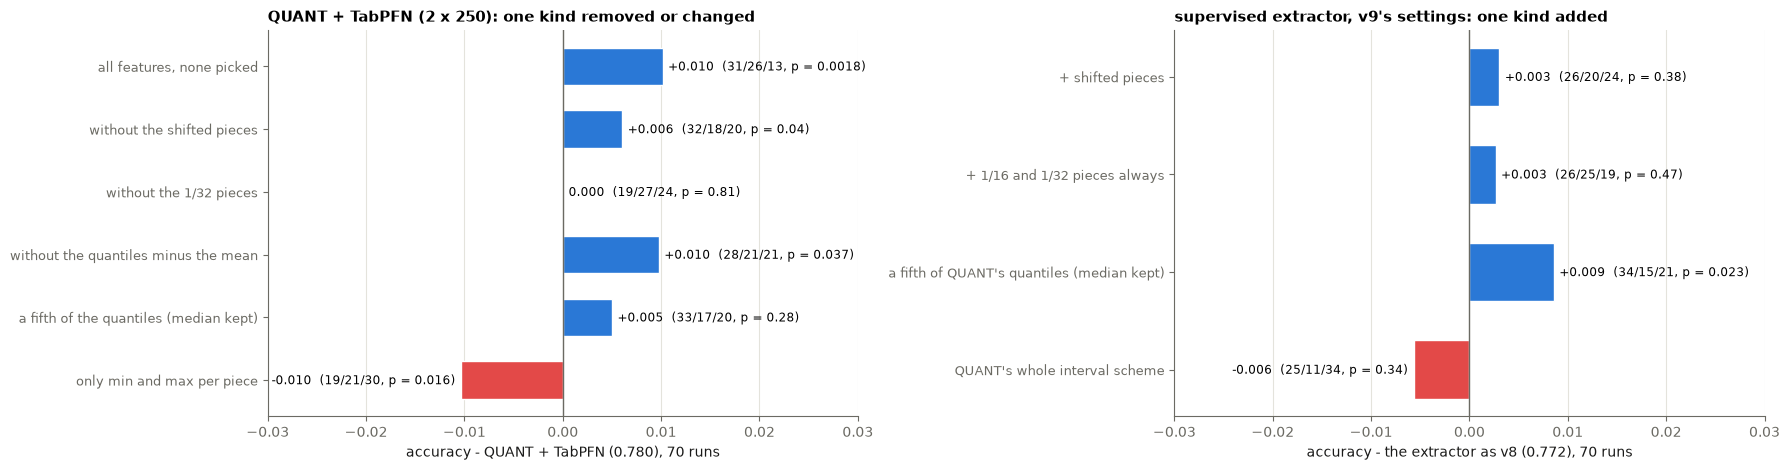

as v8                                         kept per run: min/max 41, median 1, inner 0, shifted 0, 1/32 0, lag 117, catch22 17
+ shifted pieces                              kept per run: min/max 54, median 0, inner 0, shifted 67, 1/32 0, lag 86, catch22 15
+ 1/16 and 1/32 pieces always                 kept per run: min/max 67, median 1, inner 0, shifted 0, 1/32 78, lag 56, catch22 12
a fifth of QUANT's quantiles (median kept)    kept per run: min/max 15, median 21, inner 31, shifted 0, 1/32 0, lag 100, catch22 16
QUANT's whole interval scheme                 kept per run: min/max 36, median 14, inner 85, shifted 90, 1/32 52, lag 27, catch22 6


In [16]:
abl = pd.read_csv(RESULTS_DIR / "v9-ablation_tabpfn_worst7_allcores-gpu.csv")
w = abl.pivot_table(index=key, columns="variant", values="accuracy")
LABELS = {"QA QUANT, all features": "all features, none picked",
          "Q1 QUANT - shifted": "without the shifted pieces", "Q2 QUANT - 1/32": "without the 1/32 pieces",
          "Q3 QUANT - mean-subtracted": "without the quantiles minus the mean",
          "Q4 QUANT, 20% quantiles (median kept)": "a fifth of the quantiles (median kept)",
          "Q5 QUANT, min/max only": "only min and max per piece",
          "V1 v9 + shifted": "+ shifted pieces", "V2 v9 + 1/16 and 1/32 always": "+ 1/16 and 1/32 pieces always",
          "V3 v9, 20% quantiles (median kept)": "a fifth of QUANT's quantiles (median kept)",
          "V4 v9, QUANT's intervals + summaries": "QUANT's whole interval scheme"}
SIDES = [("QUANT + TabPFN (2 x 250): one kind removed or changed", "Q0 QUANT", list(LABELS)[:6]),
         ("supervised extractor, v9's settings: one kind added", "V0 v9", list(LABELS)[6:])]
fig, axes = plt.subplots(1, 2, figsize=(18, 4.8))
for ax, (title, ref, names) in zip(axes, SIDES):
    changes = [w[n] - w[ref] for n in names]
    means = np.array([c.mean() for c in changes])
    y = np.arange(len(names))[::-1]
    ax.barh(y, means, 0.6, color=[BETTER if m > 0 else WORSE for m in means], edgecolor="white")
    for k, (n, c) in enumerate(zip(names, changes)):
        b, e, wo = wdl_counts(c)
        ax.annotate(f"{signed(c.mean())}  ({b}/{e}/{wo}, p = {stats.wilcoxon(w[n], w[ref]).pvalue:.2g})", (means[k], y[k]),
                    xytext=(4 if means[k] >= 0 else -4, -3), textcoords="offset points", fontsize=8.5,
                    ha="left" if means[k] >= 0 else "right")
    ax.axvline(0, color=MUTED, linewidth=1)
    ax.set_yticks(y, [LABELS[n] for n in names], fontsize=9)
    ax.set_xlim(-0.03, 0.03)
    ax.set_xlabel(f"accuracy - {'QUANT + TabPFN' if ref == 'Q0 QUANT' else 'the extractor as v8'} "
                  f"({w[ref].mean():.3f}), 70 runs")
    ax.set_title(title, loc="left")
    ax.grid(True, axis="x")
    ax.grid(False, axis="y")
fig.tight_layout()
plt.show()
kept = abl[abl["variant"].str.startswith("V")].groupby("variant")[
    ["kept_minmax", "kept_median", "kept_inner", "kept_shifted", "kept_1/32", "kept_lag", "kept_catch22"]].mean()
for v, r in kept.iterrows():
    print(f"{LABELS.get(v, 'as v8'):45s} kept per run: min/max {r['kept_minmax']:.0f}, median {r['kept_median']:.0f}, "
          f"inner {r['kept_inner']:.0f}, shifted {r['kept_shifted']:.0f}, 1/32 {r['kept_1/32']:.0f}, lag {r['kept_lag']:.0f}, "
          f"catch22 {r['kept_catch22']:.0f}")

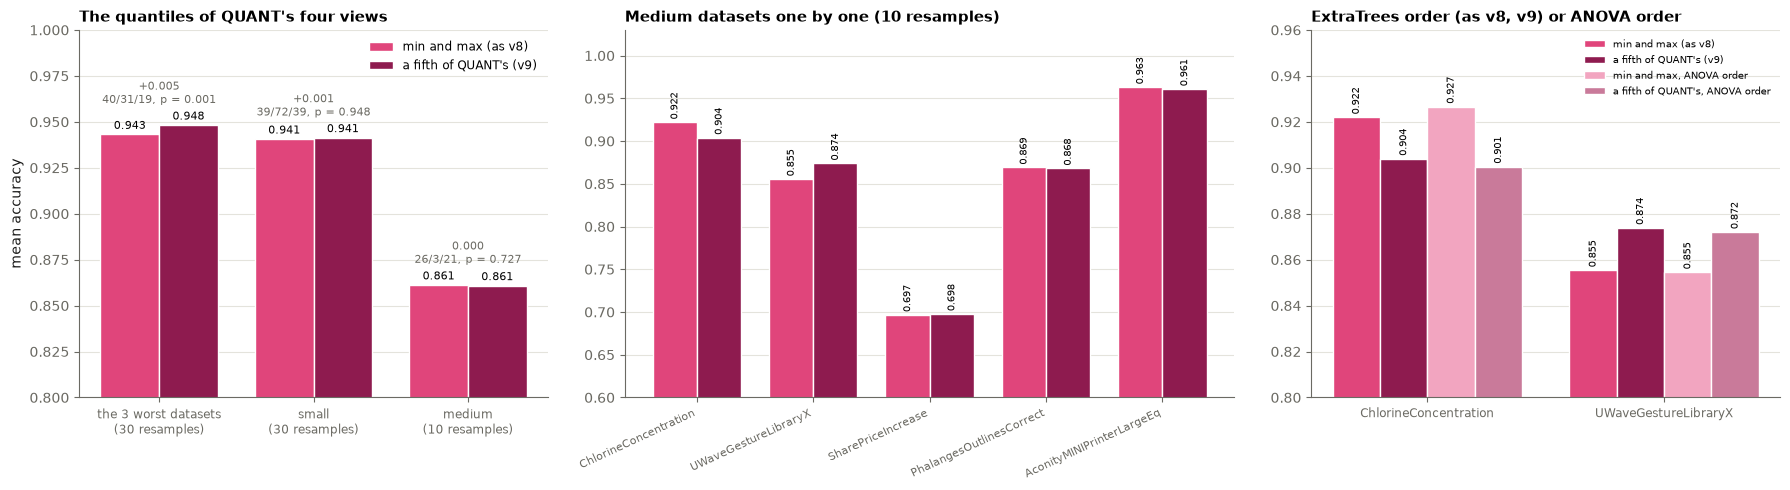

In [17]:
QLISTS = {"worst3": "the 3 worst datasets (30 resamples)", "smoke-small": "small (30 resamples)",
          "smoke-medium": "medium (10 resamples)"}
quant_test = pd.concat([pd.read_csv(RESULTS_DIR / f"v9-quantiles_tabpfn-e2f250_{lst}_allcores-gpu.csv").assign(list=lst)
                        for lst in QLISTS])
quant_test["variant"] = quant_test["variant"].map({"V0 v9": "min and max (as v8)",
                                                   "V3 v9, 20% quantiles (median kept)": "a fifth of QUANT's (v9)"})
anova_test = pd.read_csv(RESULTS_DIR / "v9-anova_tabpfn-e2f250_chlorine-uwave_allcores-gpu.csv")
anova_test["variant"] = anova_test["variant"].map({"A0 v9, ANOVA order": "min and max, ANOVA order",
                                                   "A3 v9 + 20% quantiles, ANOVA order": "a fifth of QUANT's, ANOVA order"})
Q_COLORS = {"min and max (as v8)": STEP_COLORS["v8"], "a fifth of QUANT's (v9)": STEP_COLORS["v9 (200 features)"],
            "min and max, ANOVA order": "#f2a5c0", "a fifth of QUANT's, ANOVA order": "#c97a9a"}
fig, axes = plt.subplots(1, 3, figsize=(18, 5), gridspec_kw={"width_ratios": [1, 1.3, 1]})
ax = axes[0]
for k, (lst, label) in enumerate(QLISTS.items()):
    g = quant_test[quant_test["list"] == lst].pivot_table(index=key, columns="variant", values="accuracy")
    for j, v in enumerate(["min and max (as v8)", "a fifth of QUANT's (v9)"]):
        bar = ax.bar(k + (j - 0.5) * 0.38, g[v].mean(), 0.38, color=Q_COLORS[v], edgecolor="white", label=v if k == 0 else None)
        ax.bar_label(bar, fmt="{:.3f}", padding=2, fontsize=8)
    x = g["a fifth of QUANT's (v9)"] - g["min and max (as v8)"]
    b, e, wo = wdl_counts(x)
    ax.annotate(f"{signed(x.mean())}\n{b}/{e}/{wo}, p = {stats.wilcoxon(x).pvalue:.3f}" if (x != 0).any() else "",
                (k, g.mean().max() + 0.012), ha="center", fontsize=8, color=MUTED)
ax.set_xticks(range(3), [l.replace(" (", "\n(") for l in QLISTS.values()], fontsize=8.5)
ax.set_ylim(0.8, 1.0)
ax.set_ylabel("mean accuracy")
ax.set_title("The quantiles of QUANT's four views", loc="left")
ax.legend(loc="upper right", frameon=False, fontsize=8.5)

ax = axes[1]
g = quant_test[quant_test["list"] == "smoke-medium"].groupby(["dataset", "variant"])["accuracy"].mean().unstack()
names = dataset_list("smoke-medium")
for j, v in enumerate(["min and max (as v8)", "a fifth of QUANT's (v9)"]):
    bars = ax.bar(np.arange(len(names)) + (j - 0.5) * 0.38, g.loc[names, v], 0.38, color=Q_COLORS[v], edgecolor="white")
    ax.bar_label(bars, fmt="{:.3f}", padding=2, fontsize=7.5, rotation=90)
ax.set_xticks(range(len(names)), names, rotation=25, ha="right", fontsize=8)
ax.set_ylim(0.6, 1.03)
ax.set_title("Medium datasets one by one (10 resamples)", loc="left")

ax = axes[2]
both_orders = pd.concat([quant_test[quant_test["dataset"].isin(["ChlorineConcentration", "UWaveGestureLibraryX"])], anova_test])
g = both_orders.groupby(["dataset", "variant"])["accuracy"].mean().unstack()
order = ["min and max (as v8)", "a fifth of QUANT's (v9)", "min and max, ANOVA order", "a fifth of QUANT's, ANOVA order"]
for j, v in enumerate(order):
    bars = ax.bar(np.arange(2) + (j - 1.5) * 0.2, g[v], 0.2, color=Q_COLORS[v], edgecolor="white", label=v)
    ax.bar_label(bars, fmt="{:.3f}", padding=2, fontsize=7.5, rotation=90)
ax.set_xticks(range(2), ["ChlorineConcentration", "UWaveGestureLibraryX"], fontsize=8.5)
ax.set_ylim(0.8, 0.96)
ax.set_title("ExtraTrees order (as v8, v9) or ANOVA order", loc="left")
ax.legend(loc="upper right", frameon=False, fontsize=7.5)
for a in axes:
    a.grid(True, axis="y")
    a.grid(False, axis="x")
fig.tight_layout()
plt.show()

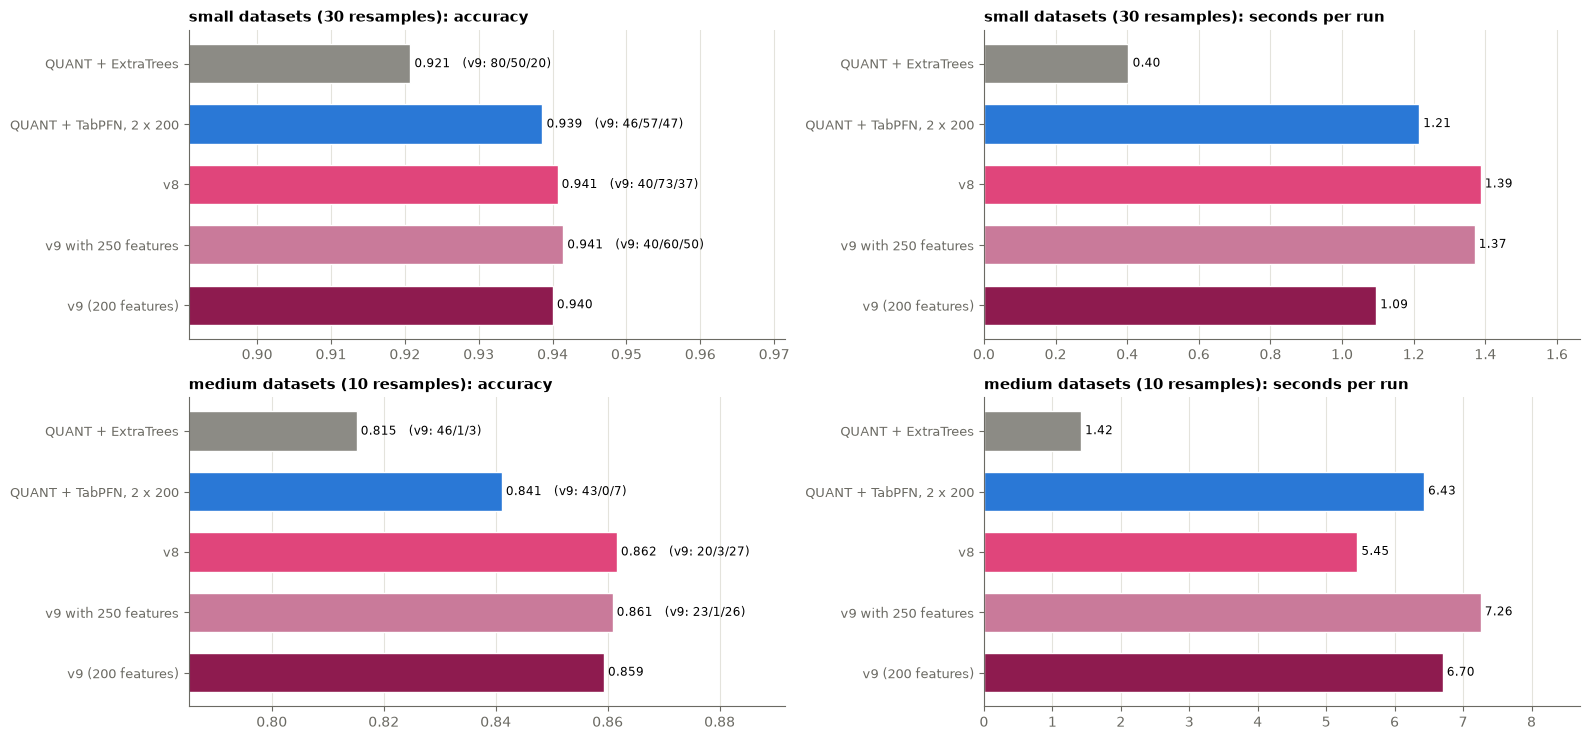

In [18]:
BUDGET_LISTS = {"smoke-small": 30, "smoke-medium": 10}
v9_250 = quant_test[quant_test["variant"] == "a fifth of QUANT's (v9)"].rename(columns={"time": "total_time"})
BUDGET = {"QUANT + ExtraTrees": full_runs["QUANT + ExtraTrees"],
          "QUANT + TabPFN, 2 x 200": None,
          "v8": v8_full,
          "v9 with 250 features": v9_250,
          "v9 (200 features)": full_runs["v9 (200 features)"]}
B_COLORS = [STEP_COLORS["QUANT + ExtraTrees"], "#2a78d6", STEP_COLORS["v8"], "#c97a9a", STEP_COLORS["v9 (200 features)"]]
fig, axes = plt.subplots(2, 2, figsize=(16, 7.5))
for row, (lst, resamples) in enumerate(BUDGET_LISTS.items()):
    BUDGET["QUANT + TabPFN, 2 x 200"] = pd.read_csv(RESULTS_DIR / f"v3-quant_tabpfn-e2f200-both_{lst}_allcores-gpu.csv"
                                                    ).rename(columns={"time": "total_time"})
    runs = {n: r[r["dataset"].isin(dataset_list(lst)) & (r["resample"] < resamples)] for n, r in BUDGET.items()}
    ref = runs["v9 (200 features)"].set_index(key)["accuracy"]
    for col, (metric, label, fmt) in enumerate([("accuracy", "accuracy", "{:.3f}"), ("total_time", "seconds per run", "{:.2f}")]):
        ax = axes[row, col]
        values = np.array([runs[n][metric].mean() for n in BUDGET])
        y = np.arange(len(BUDGET))[::-1]
        bars = ax.barh(y, values, 0.65, color=B_COLORS, edgecolor="white")
        labels = [fmt.format(v) for v in values]
        if metric == "accuracy":                 # + better / equal / worse runs of v9 (200) against each
            for k, n in enumerate(BUDGET):
                if n != "v9 (200 features)":
                    b, e, wo = wdl_counts(ref - runs[n].set_index(key)["accuracy"].reindex(ref.index))
                    labels[k] += f"   (v9: {b}/{e}/{wo})"
            ax.set_xlim(values.min() - 0.03, values.max() + 0.03)
        else:
            ax.set_xlim(0, values.max() * 1.2)
        ax.bar_label(bars, labels=labels, padding=3, fontsize=8.5)
        ax.set_yticks(y, list(BUDGET), fontsize=9)
        ax.set_title(f"{LIST_NAMES[lst]} ({resamples} resamples): {label}", loc="left")
        ax.grid(True, axis="x")
        ax.grid(False, axis="y")
fig.tight_layout()
plt.show()

Note: the accuracy axes do not start at 0; times of the feature tests and of the full runs come from different
sessions (about 10% variation).

- **Where v8's time goes:** the features of the training data (the candidates and the selection, including the fill
  rounds) take 2.1 hours, more than TabPFN itself (2.0) and twelve times v4's features (0.2). v9 brings them down to
  1.75 hours, although it has more quantile candidates: catch22 and the templates are computed once for all fill
  rounds (identical results), and the fill rounds stop at 1/16. On the 15 datasets that reached 1/32, stopping at
  1/16 keeps the accuracy (0.927 against 0.926, p = 0.52) and halves the time (4.2 against 8.4 s per run). TabPFN
  takes about the same time in v9 (2.1 hours): 200 features on every dataset against v8's smaller budget on the
  large ones.
- **Which of QUANT's features:** only the quantiles matter. Reducing QUANT to min and max costs TabPFN about 0.01;
  without the 1/32 pieces nothing changes; without the shifted pieces or the quantiles minus the mean TabPFN is even
  better: these near-copies take places among the 250. A fifth of QUANT's quantiles (median kept) loses nothing
  against all of them, and added to the extractor's candidates it is the only change that helps (+0.009); the
  selection then keeps about 20 medians and 30 inner quantiles per run.
- **The check on the other lists:** the fifth of QUANT's quantiles helps the 3 worst datasets and changes nothing
  on the small and medium lists on average, with UWaveGestureLibraryX gaining and ChlorineConcentration losing
  about 0.02 each. On ChlorineConcentration the quantiles take places from lag-d features that TabPFN classifies
  better with; ordering the candidates by ANOVA alone instead of the ExtraTrees importance does not change that.
- **200 features:** as accurate as v9 with 250 and as v8 on the small and medium lists, and faster than 250 (1.1
  against 1.4 s per run on the small list, 6.7 against 7.3 s on the medium list, from different sessions);
  QUANT's own features at the same 2 x 200 are as good on the small datasets but clearly worse on the medium ones.

## 13. Conclusions

**Accuracy and time (section 3)**, mean accuracy / time per run; the small list with 30 resamples (v5 has only 3):

| | QUANT + ExtraTrees | v4 (cheap TabPFN) | v5-templates | v6 | v7 | v8 | v9 (200 features) |
|---|---|---|---|---|---|---|---|
| 3 worst (90 runs) | 0.905 / 0.55 s | 0.844 / 0.97 s | 0.938 / 0.67 s | 0.945 / 0.78 s | **0.946** / 0.93 s | 0.943 / 1.02 s | 0.944 / 1.10 s |
| small (150 runs) | 0.921 / 0.40 s | 0.936 / 0.90 s | - | 0.939 / 0.72 s | **0.945** / 1.36 s | 0.941 / 1.38 s | 0.940 / 1.09 s |
| medium (15 runs) | 0.815 / 1.39 s | 0.862 / 4.84 s | 0.861 / 5.64 s | 0.861 / 6.46 s | 0.857 / 4.67 s | 0.861 / 4.72 s | **0.863** / 6.56 s |

- **v5, the sources one by one, fixes the 3 worst datasets.** The selection alone and the shape-only view stay below
  v4 there (0.829 vs 0.844); catch22 lifts them to 0.893 (ShapeletSim 0.997) and the pattern templates to 0.938
  (ToeSegmentation1 0.916, ToeSegmentation2 0.899), better than v4 in 88 of 90 runs and now also better than QUANT +
  ExtraTrees (0.984, 0.854, 0.876). On the medium list all v5 steps match v4 (0.861-0.862); on the small list they
  stay below it (0.919-0.926 against 0.937, 3 resamples) because of Beef alone (0.744-0.767 against 0.822).
- **v6: a leaner pool and a full budget.** Without the shape-only view and lag-4 (they mostly repeat other views,
  section 7), with the budget filled up to 250 and catch22 on a shortened copy of long, smooth series: the 3 worst
  0.945 (better than v4 in all 90 runs), the small list 0.939 (Beef 0.852 against 0.833: with 30 training cases the
  strict relevance check had left only about 100 features), the medium list 0.861. (Its medium time comes from a slow
  run of the laptop: times vary by about 10% between runs, also on datasets a change does not touch.)
- **v7: ExtraTrees importance in the selection** helps the small datasets most: 0.945 (Beef 0.883; better than v4 in
  46, equal in 62, worse in 42 of 150 runs), the 3 worst 0.946, the medium list 0.857. The ExtraTrees fit costs about
  0.6 s per run on the small datasets (the fixed start-up cost of a forest on all cores).
- **v8: the lag-d views chosen per dataset.** Adding lag-4 back for every dataset (v8-lag4) helps the medium list
  (0.860) but costs the small one (0.940, Beef 0.861): which lags help depends on the dataset. With the lag ladder
  in the candidate pool and the selection deciding: small 0.941, medium 0.861, the 3 worst 0.943. Section 10: long
  series with slow movements use long lags (UWaveGestureLibraryX: lag-64 22% and lag-32 17% of the kept features),
  short series short lags (ItalyPowerDemand: lag-2 and lag-4 about 15% each).
- **v9: v8 made faster, with 200 features and more quantiles** (from its full run in notebook 06): the two speed
  fixes (catch22 and the templates computed once for all fill rounds; finer pieces only down to 1/16), 200 features
  on every dataset instead of v8's size rule, and a fifth of QUANT's quantiles, median kept, on QUANT's four views.
  Here it matches v8: the 3 worst 0.944 (ShapeletSim 1.000, ToeSegmentation1 0.917, ToeSegmentation2 0.916), the
  small list 0.940 (Beef 0.858), the medium list 0.863. With 3 resamples the small list shows 0.929 (section 3), with
  30 the gap to v8 is gone: one test case of Beef is 3.3 points. Its times come from the full run, the other
  versions' from their own smoke runs (about 10% variation between sessions); on the medium list its 200 features
  cost TabPFN more time than v8's 150 there (6.6 against 4.7 s). The quantiles come from a scratch test
  (`experiments.md`, v9): of the features QUANT has and v8 does not, only the median and inner quantiles helped
  TabPFN. v9 is the version compared with v4 and QUANT + ExtraTrees on all 142 datasets in notebook 06.
- **v8 on all 142 datasets and its 10 worst (section 11):** better than QUANT + ExtraTrees on 122 of 142 datasets
  (p = 2e-19) and than v4 on 97 (p = 3e-10), in 5.0 hours. Its losses are small (at most -0.029); on the 10
  largest the cause is the feature set, not TabPFN or the fill: TabPFN on QUANT's full set is as accurate as
  ExtraTrees (0.778 against 0.777), on v8's 250 features it gets 0.765. v9's median and inner quantiles halve that
  gap (0.771).
- **From v8 to v9 (section 12):** of QUANT's features only the quantiles help TabPFN, and a fifth of them (median
  kept) is enough; v9 takes less time than v8 because the features of the training data no longer recompute
  catch22 and the templates for every fill round, and 200 features are as accurate as 250 on the small and medium
  lists.

**What is kept and dropped (sections 4 to 9, v5-templates).**
- Most interval candidates are dropped as irrelevant: about half on the small datasets, a third on the medium ones
  and 82-91% on the 3 worst, where only a few pieces carry the short pattern (section 5).
- **catch22 and the templates are kept far more often than any interval source:** templates 74-77% of the time,
  catch22 about 30-40% (section 5); in catch22, the features of the change view are kept as often as those of the
  series (section 8).
- **The shape view mostly repeated the series** (75-76% of the near-copies of each are copies of the other) and
  **lag-4 mostly repeated the smoothed change** (69%, section 7): the reason they are gone from v6.
- On the 3 worst datasets, the whole-series and half pieces of the smoothed change (spread) and of lag-16 are the
  interval features that survive; the 1/8 pieces are almost never kept (section 6).

Caveat: the medium list has 3 resamples; the small list (v6 to v9) and the 3 worst datasets have 30. The full
benchmark of v4, v8 and v9 is in notebook 06.